# <center> **MATH&ML-11. Кластеризация и техники понижения размерности. Часть II**

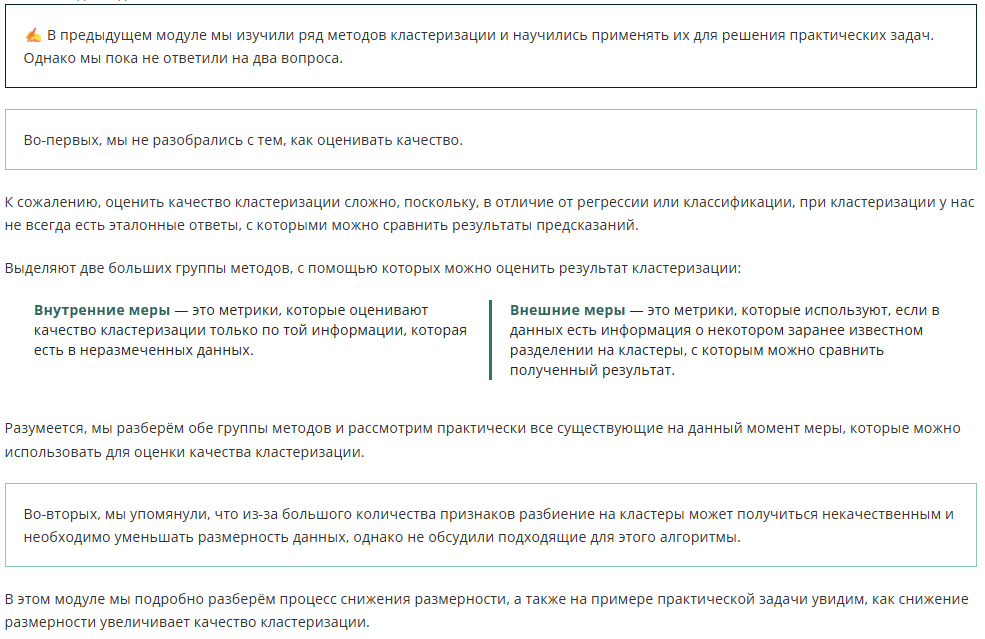

## <center>  2. Оценка качества кластеризации: внутренние меры

В библиотеке *sklearn* реализованы три наиболее популярные метрики:
* **коэффициент силуэта (Silhouette Coefficient)**;
* **индекс Калински — Харабаса (Calinski-Harabasz Index)**;
* **индекс Дэвиса — Болдина (Davies-Bouldin Index)**.

Эти метрики мы рассмотрим максимально подробно, а также вычислим каждую из них «вручную». Важно отметить, что вам не потребуется в будущем реализовывать подобные вычисления самостоятельно, однако разбор вычислительных примеров поможет лучше разобраться в том, как рассчитываются значения и каков их смысл.

## <center> **Коэффициент силуэта**

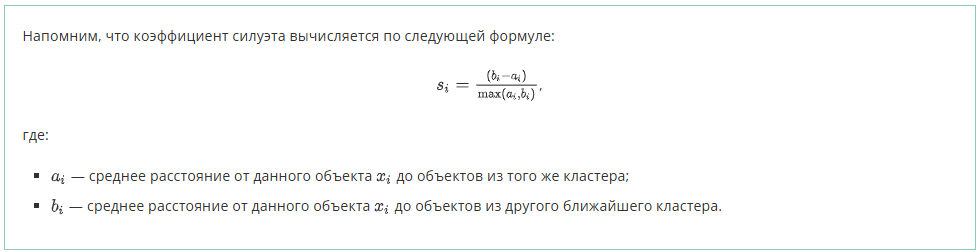

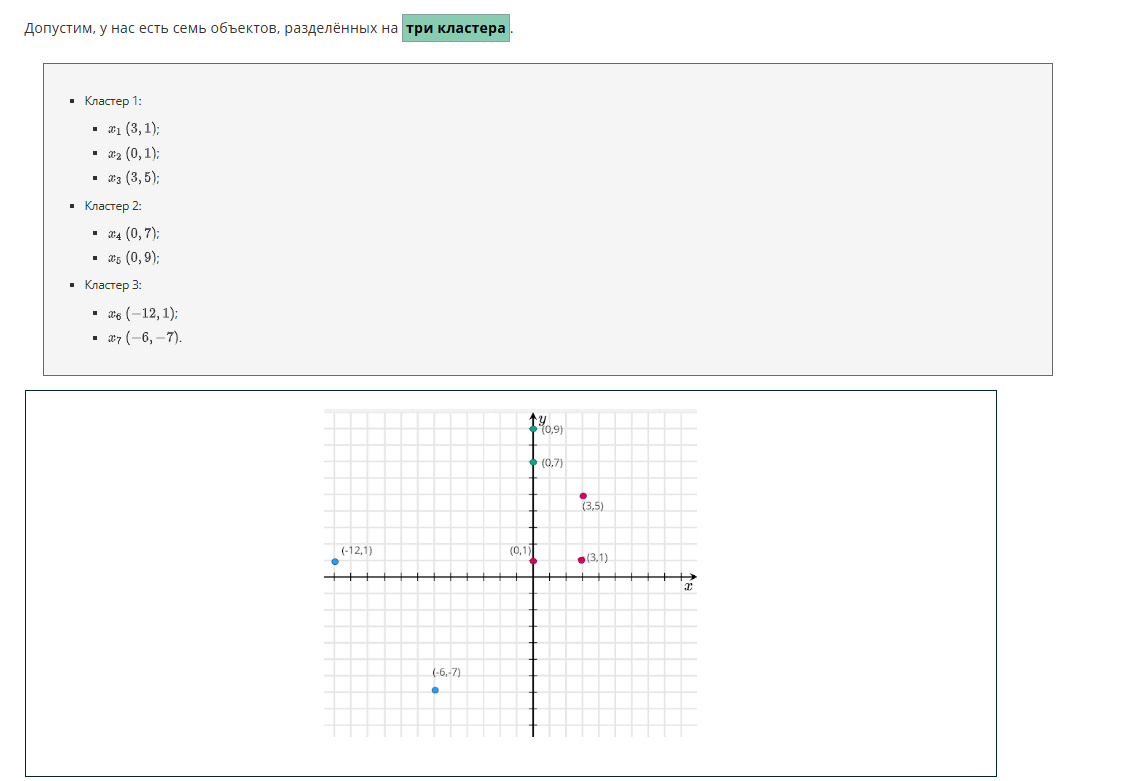

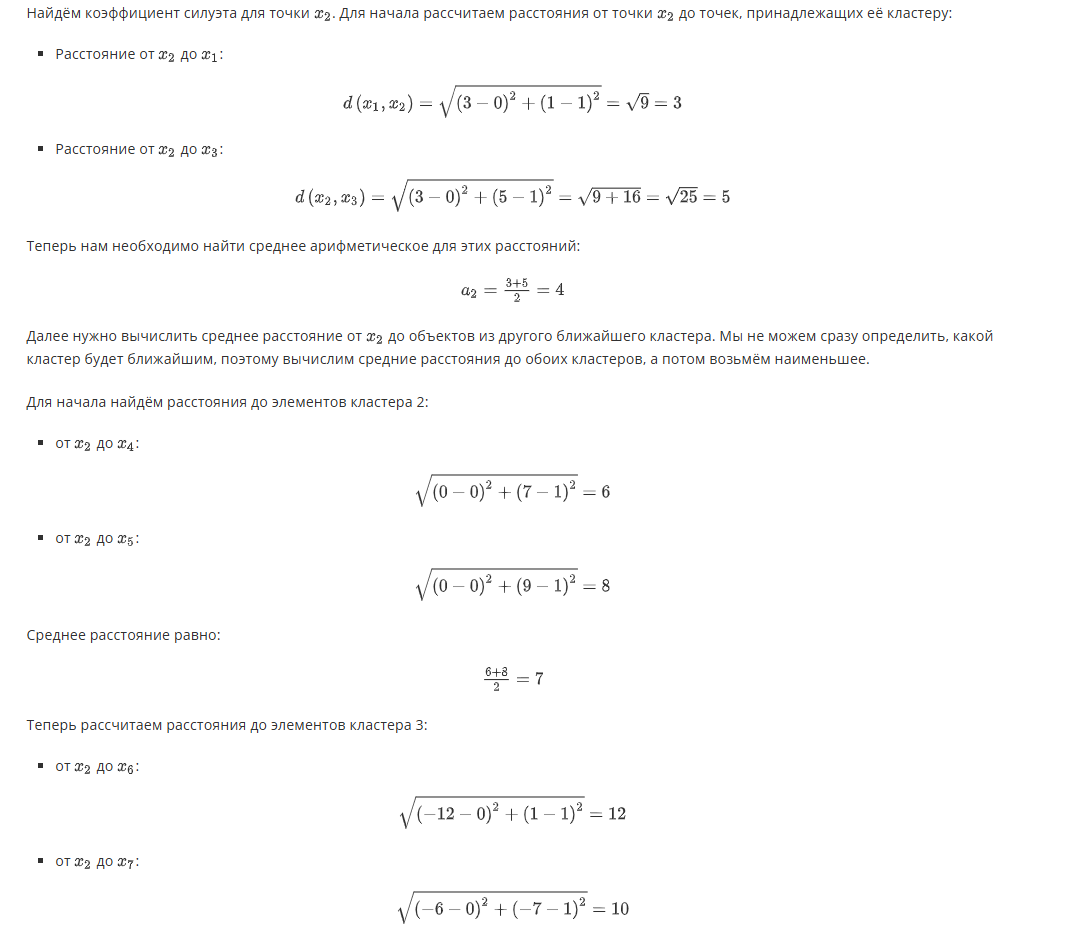

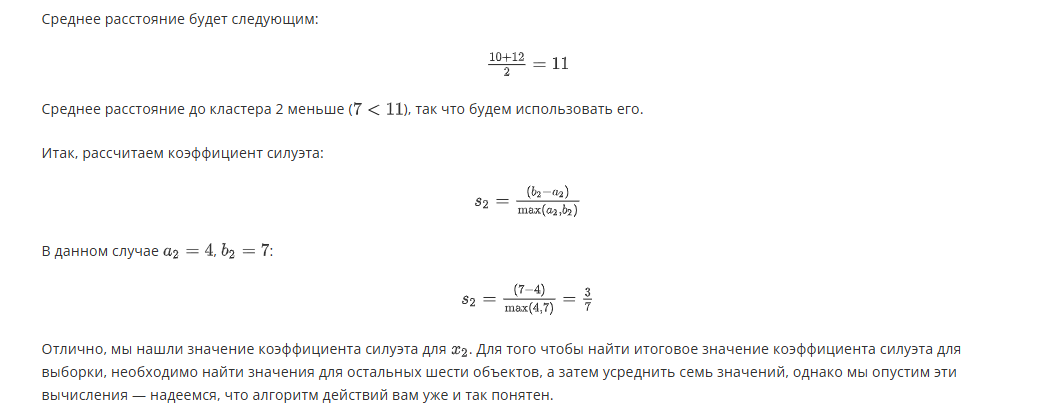

При решении практических задач вы будете использовать уже готовые алгоритмы на Python. Для вычисления коэффициента силуэта в библиотеке sklearn используется [silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html):

```python
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#определяем алгоритм кластеризации
km = KMeans(n_clusters=3, random_state=42)
#обучаем его на наших данных
km.fit_predict(X)
#вычисляем значение коэффициента силуэта
score = silhouette_score(X, km.labels_, metric='euclidean')
```

Значение коэффициента силуэта всегда находится в диапазоне [−1,1].
* Значение близко к −1: объекты в кластерах разрознены, и в целом кластерную структуру не удалось выделить.
* Значение близко к 0: кластеры пересекаются друг с другом.
* Значение близко к 1: чёткая кластерная структура с «плотными», отделёнными друг от друга кластерами.

Также мы можем изобразить распределение коэффициентов силуэта для объектов отдельных кластеров.

Например, визуализация для двух кластеров будет такой:

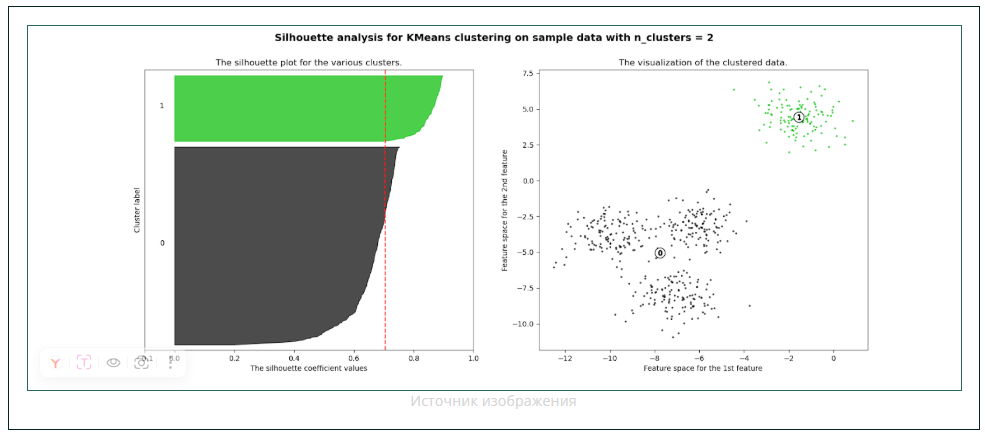

>Пояснение. На графике слева красной пунктирной линией здесь и далее отмечено среднее значение коэффициента силуэта для данного случая кластеризации. Разными цветами (серый и зелёный) визуализированы распределения значений коэффициентов силуэта для объектов соответствующих кластеров. На графике справа отмечены объекты, окрашенные в разные цвета в соответствии с их принадлежностью к кластерам.

Здесь мы видим, что «нулевой» кластер (серого цвета) включает в себя точки с более маленькими значениями. Это довольно хорошо соотносится с правой визуализацией, т. к. в сером кластере точки местами разрознены сильнее, чем в зелёном.

Для случая трёх кластеров ситуация будет следующей:

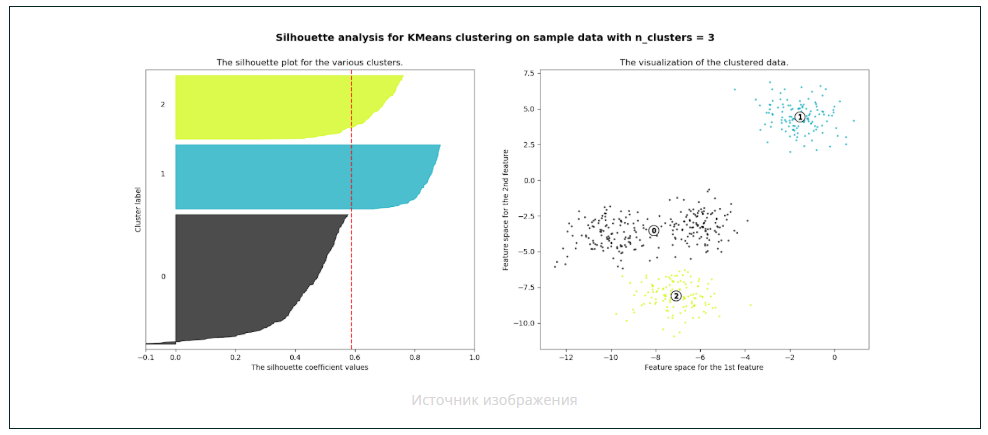

Довольно естественно (если посмотреть на график справа), что голубой кластер показывает наилучшую согласованность. У точек серого кластера коэффициенты всё так же самые низкие — явно напрашивается его разделение на ещё два кластера, и это действительно улучшает качество, так как значения коэффициентов силуэта увеличились (в новых сером и жёлтом кластерах они выше, чем были в предыдущем сером):

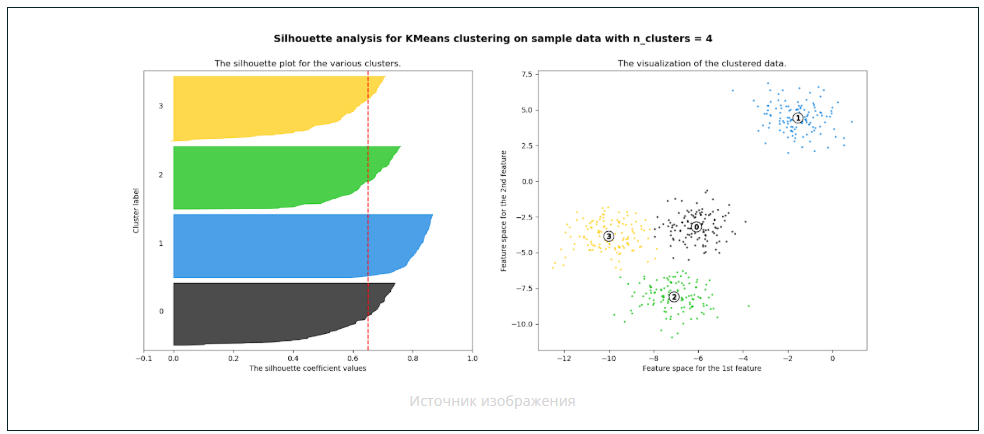

## <center> **Индекс Калински — Харабаса**

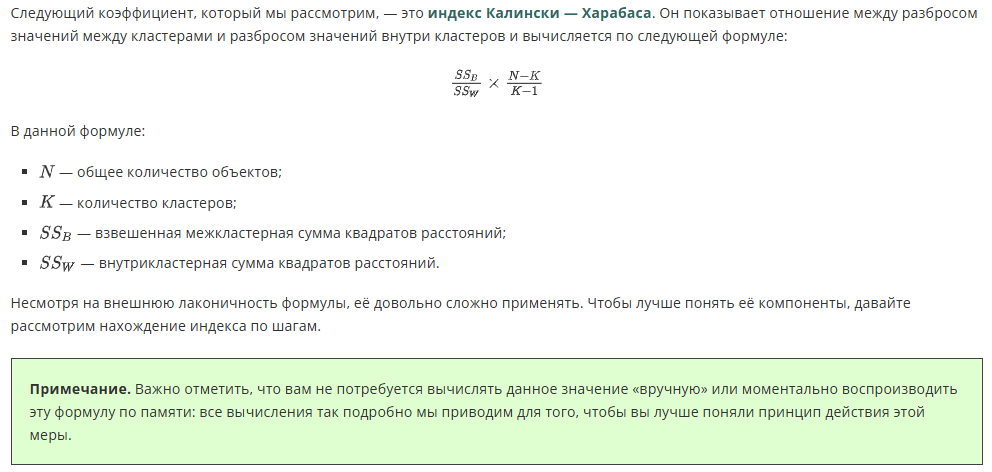

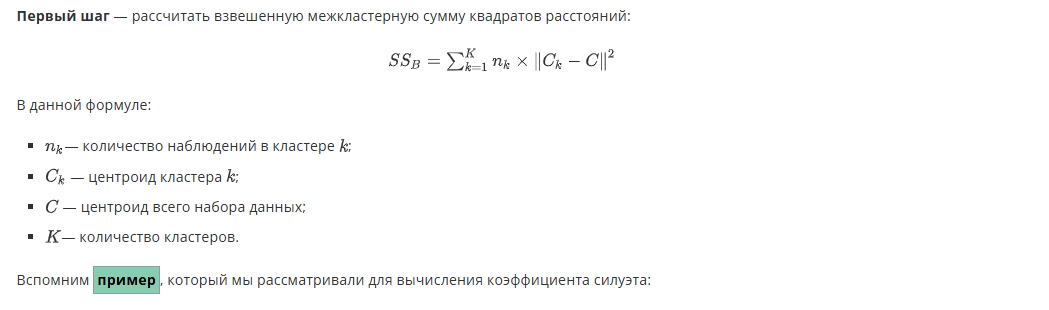

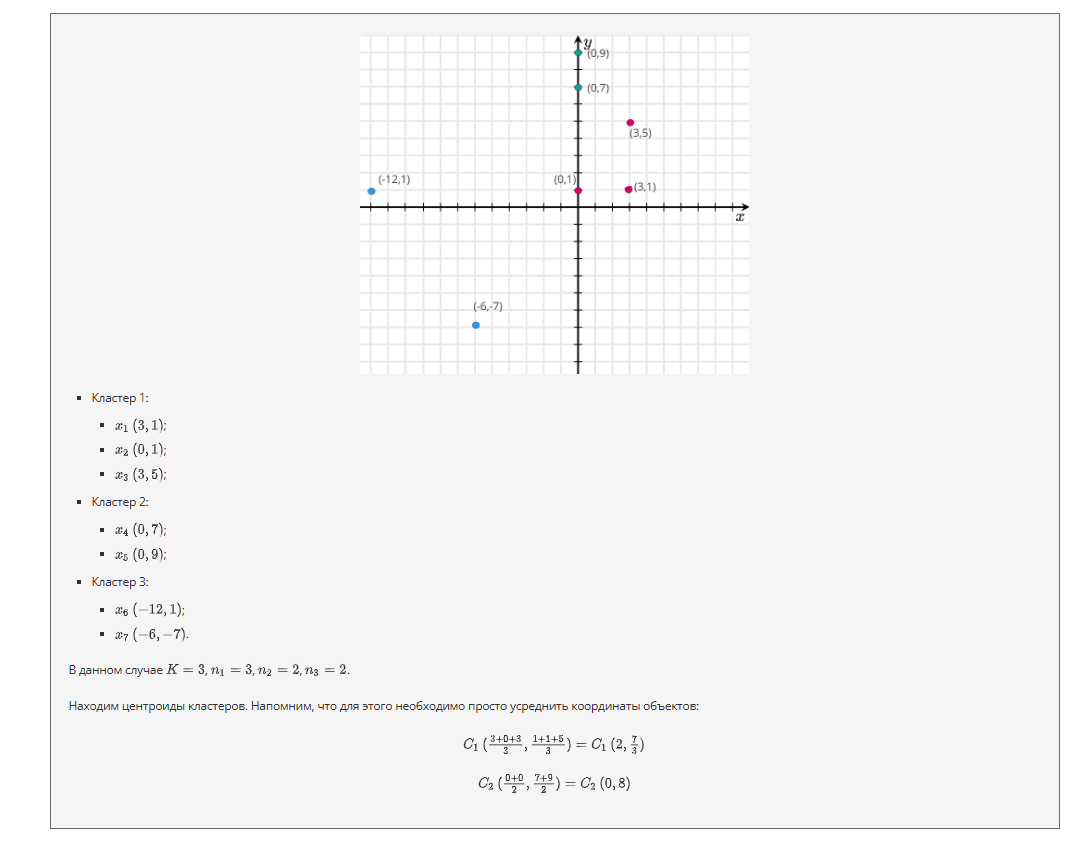

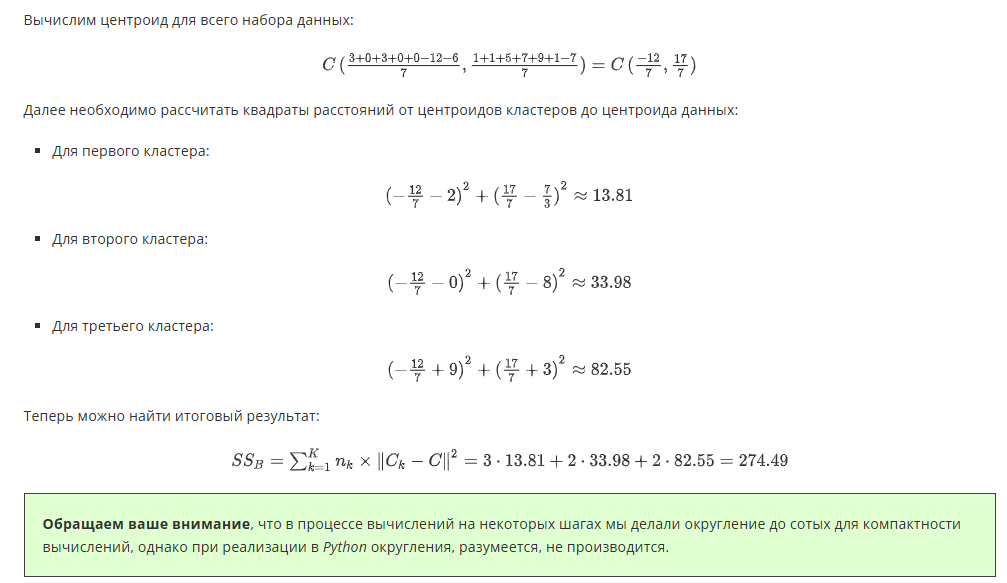

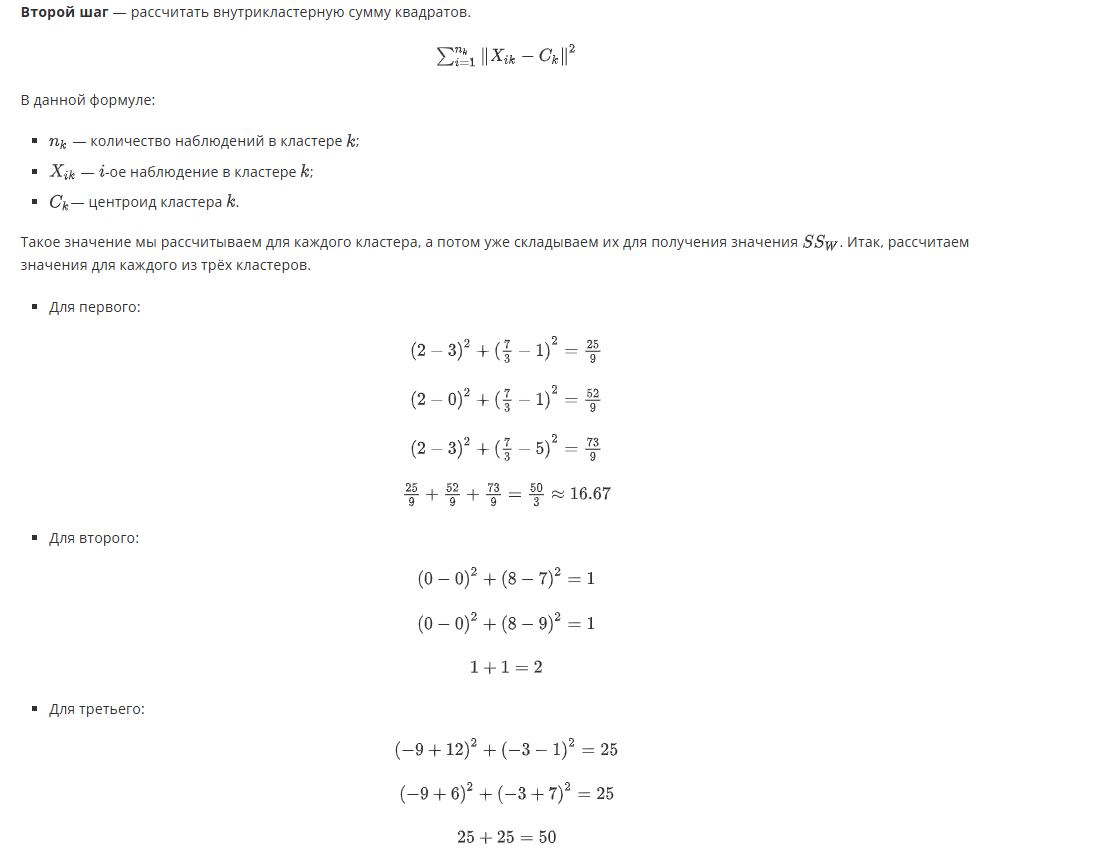

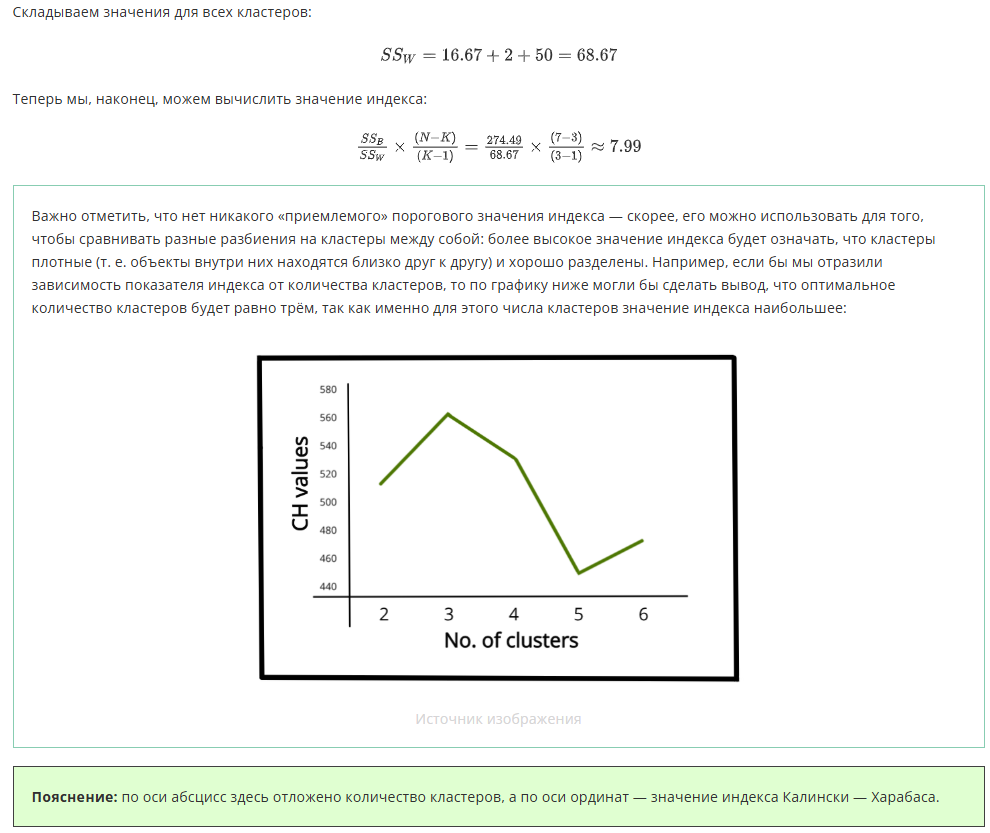

В библиотеке sklearn данный алгоритм реализуется с помощью метода [calinski_harabasz_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html):

```python
#определяем алгоритм кластеризации
km = KMeans(n_clusters=3, random_state=42)
#обучаем его на наших данных
km.fit_predict(X)
#вычисляем значение коэффициента Калински — Харабаса
score = calinski_harabasz_score(X, km.labels_)
```

## <center> **Индекс Дэвиса — Болдина**

Перейдём к последнему из трёх наиболее важных для нас коэффициентов — индексу Дэвиса — Болдина. Рассмотрим процесс его вычисления сразу по шагам, так как он реализуется достаточно сложно.

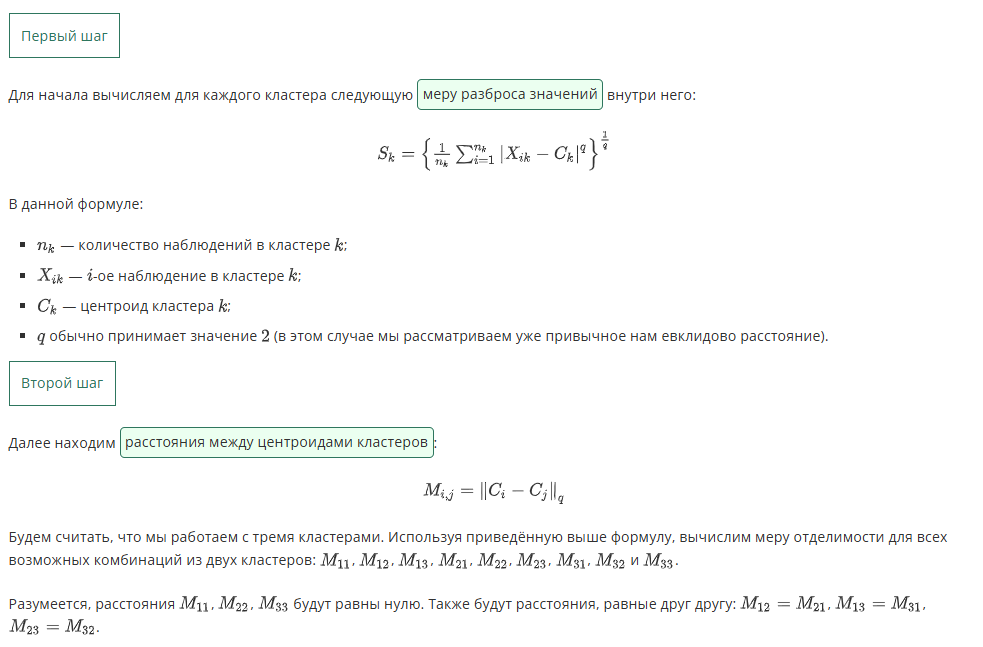

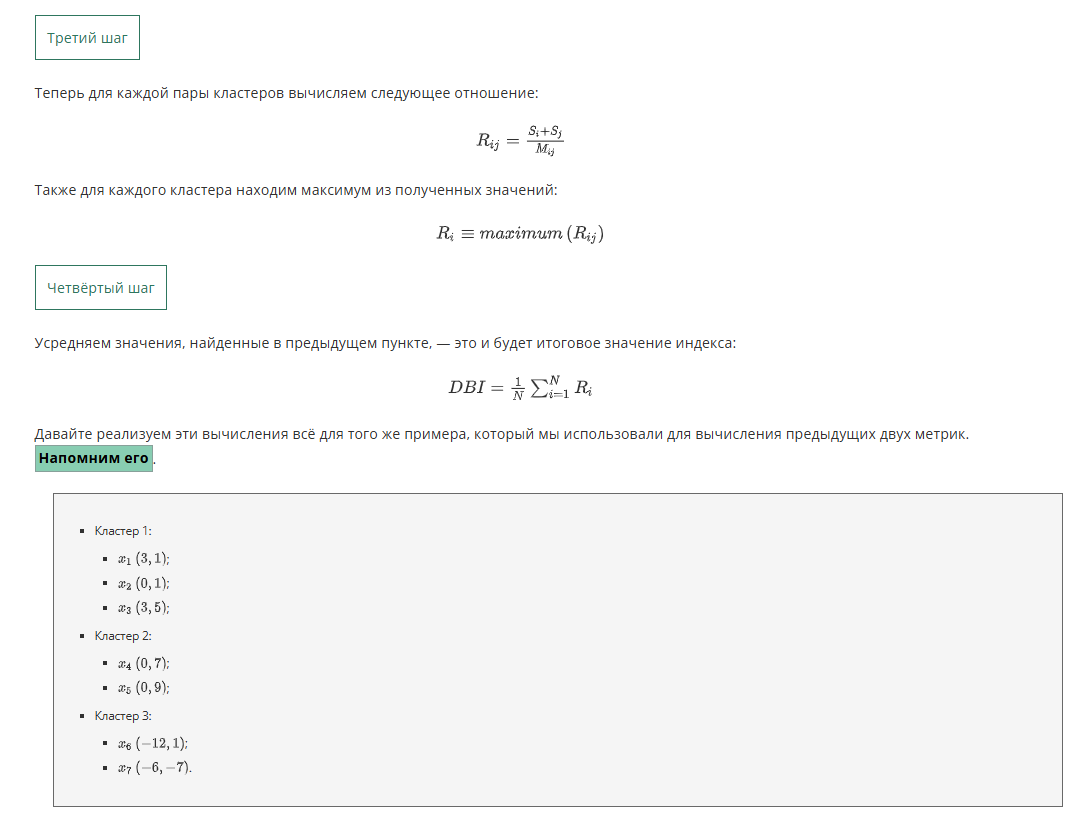

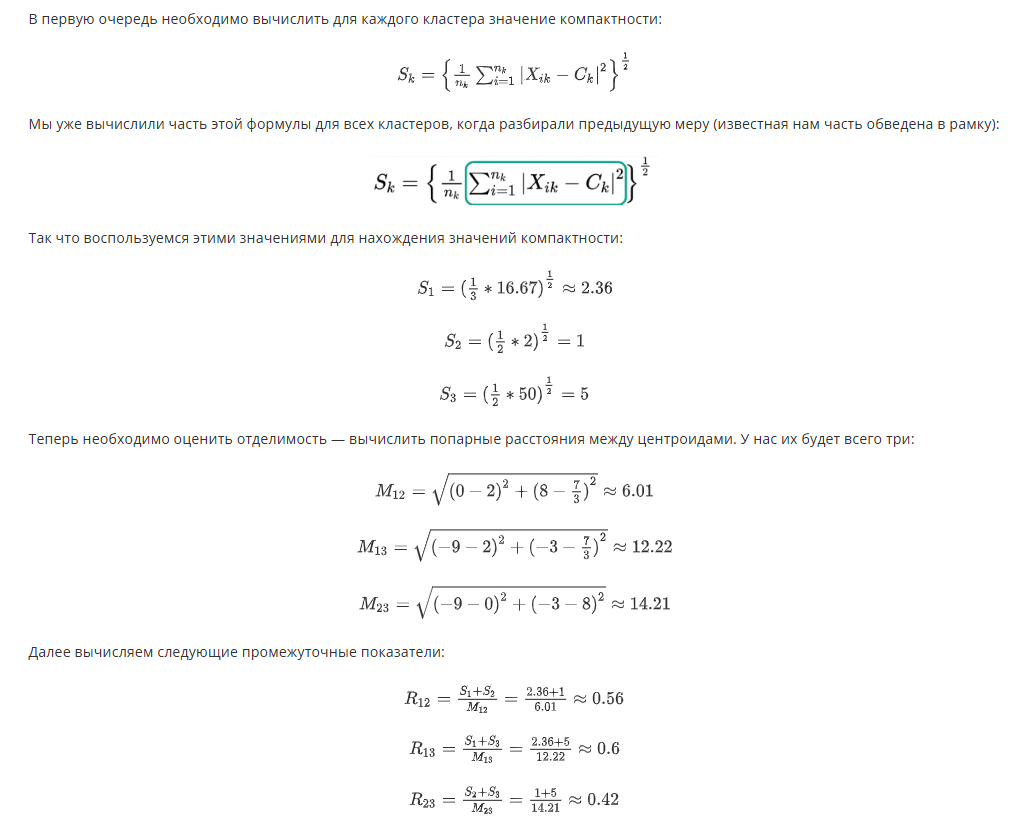

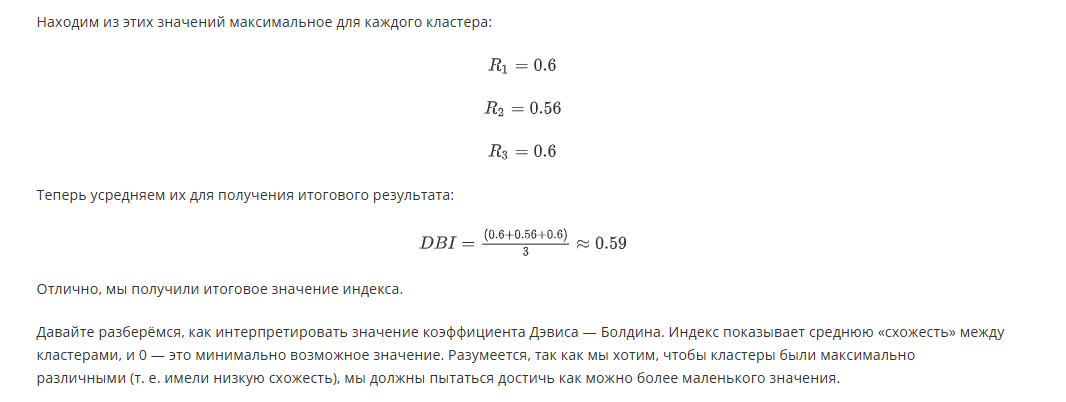

В библиотеке sklearn индекс Дэвиса — Болдина реализуется с помощью метода [davies_bouldin_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html):

```python
#определяем алгоритм кластеризации
km = KMeans(n_clusters=3, random_state=42)
#обучаем его на наших данных
km.fit_predict(X)
#вычисляем значение коэффициента Дэвиса — Болдина
score = davies_bouldin_score(X, km.labels_)
```

Итак, мы рассмотрели три наиболее популярных метрики, которые обычно вычисляются при кластеризации и заложены в библиотеке sklearn. Однако есть ещё ряд показателей, с которыми вы можете столкнуться в различных источниках. Несмотря на то что они не реализованы в готовых библиотеках Python, о них часто упоминают, когда речь идёт об оценке качества кластеризации. Мы не будем подробно рассматривать вычисления для них, однако ознакомимся с их сутью, чтобы вы могли составить полную картину.

## <center> **Внутрикластерное расстояние**

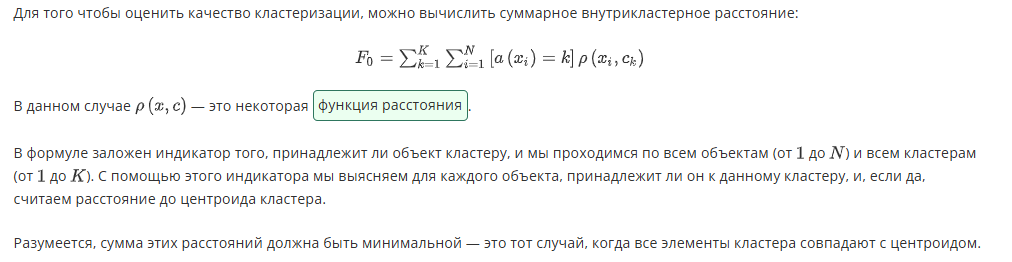

## <center> **Межкластерное расстояние**

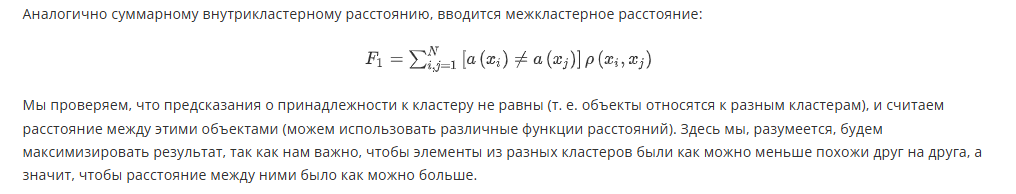

## <center> **Отношение расстояний**

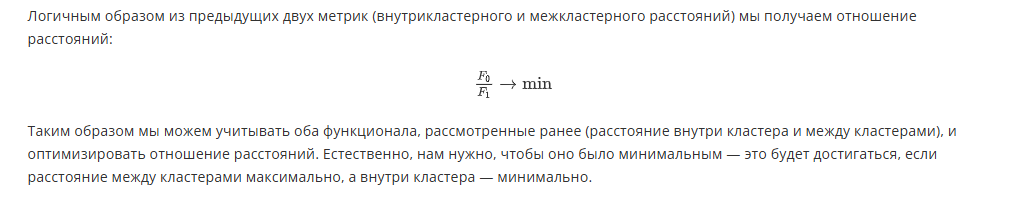

---

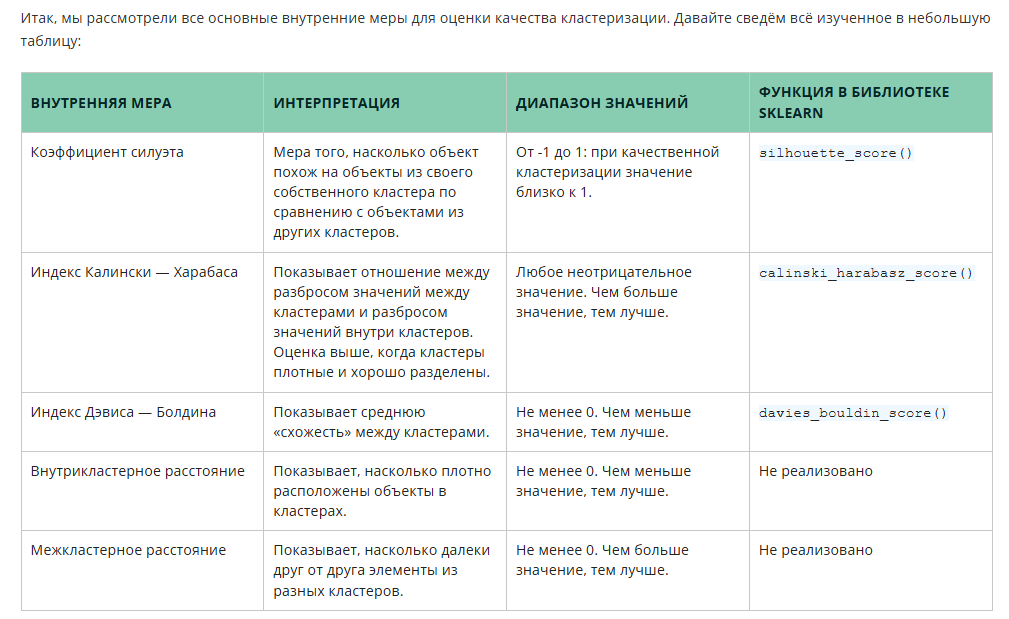

---

# <center> **3. Оценка качества кластеризации: внешние меры**

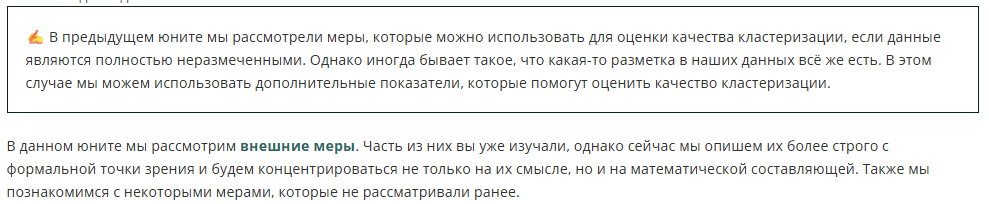

## <center> **Индекс Рэнда**

Первая внешняя мера, которую мы рассмотрим, — это **индекс Рэнда**. В целом, это не совсем метрика для оценки качества кластеризации: индекс Рэнда — это мера сходства между двумя кластеризациями. Однако, так как он позволяет сравнить два разбиения на кластеры, мы можем использовать его для сравнения фактических меток классов и прогнозируемых меток кластеров, тем самым оценивая качество наших алгоритмов.

Данный индекс сравнивает фактическое разбиение и результат применения алгоритма кластеризации и оценивает, сколько пар, находившихся в одном или в разных кластерах, сохранили это состояние.

Индекс Рэнда вычисляется по следующей формуле:

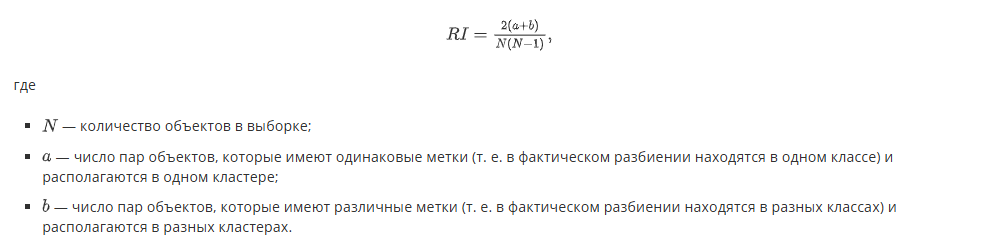

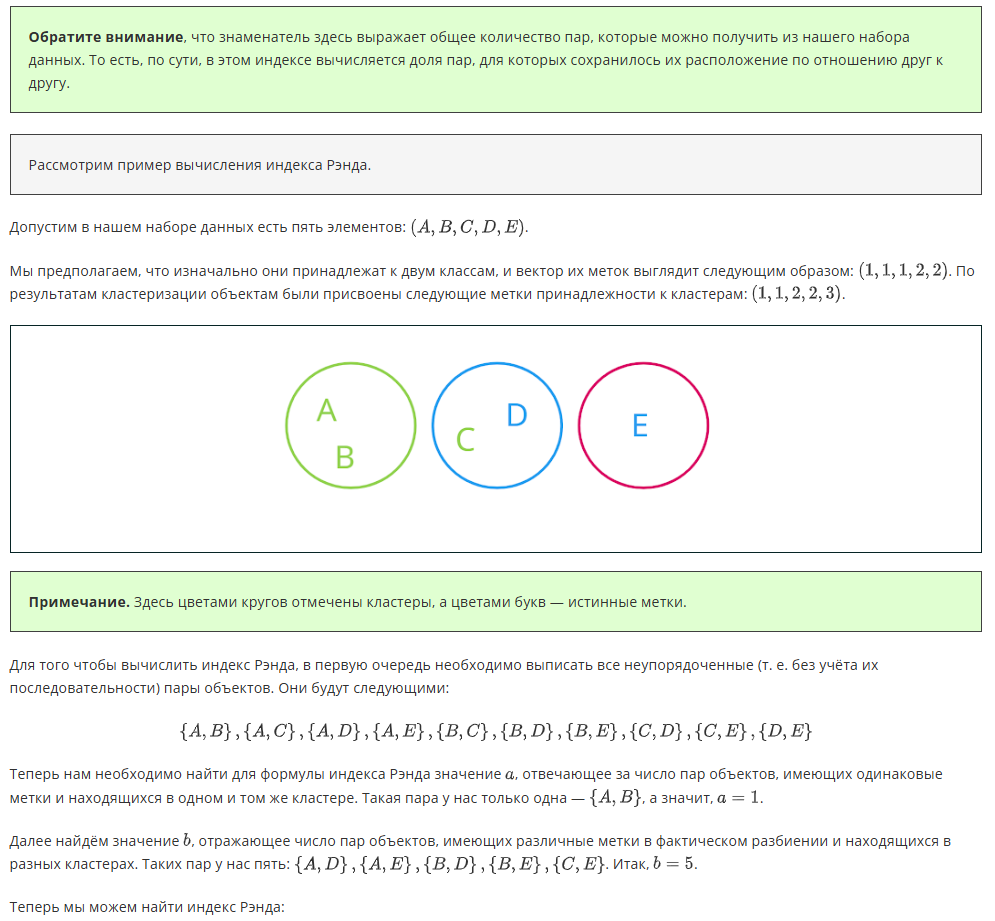

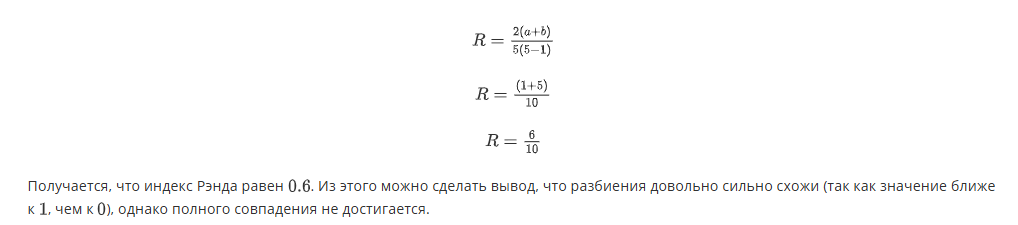

Для вычисления индекса Рэнда с помощью библиотеки sklearn можно использовать метод [rand_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.rand_score.html):



In [1]:
from sklearn.metrics import rand_score
print(rand_score([1, 1, 1, 2, 2], [1, 1, 2, 2, 3]))

0.6


Также используют **скорректированный индекс Рэнда (Adjusted Rand Index)**:

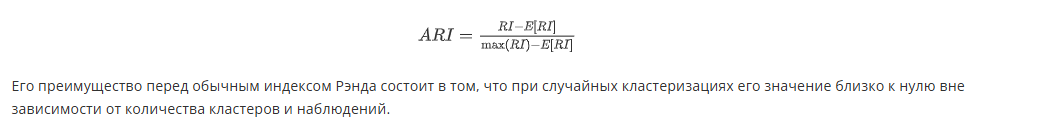

Исправленный индекс Рэнда в sklearn представлен через метод [adjusted_rand_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html#sklearn.metrics.adjusted_rand_score).

Интерпретация скорректированного индекса Рэнда:
* Отрицательные значения индекса говорят о различных, независимых разбиениях.
* Значения, близкие к нулю, являются индикаторами случайного разбиения.
* Положительные значения показывают схожесть разбиений (значение, равное , получается при полном совпадении кластеризаций).

## <center> **Нормализованная взаимная информация**

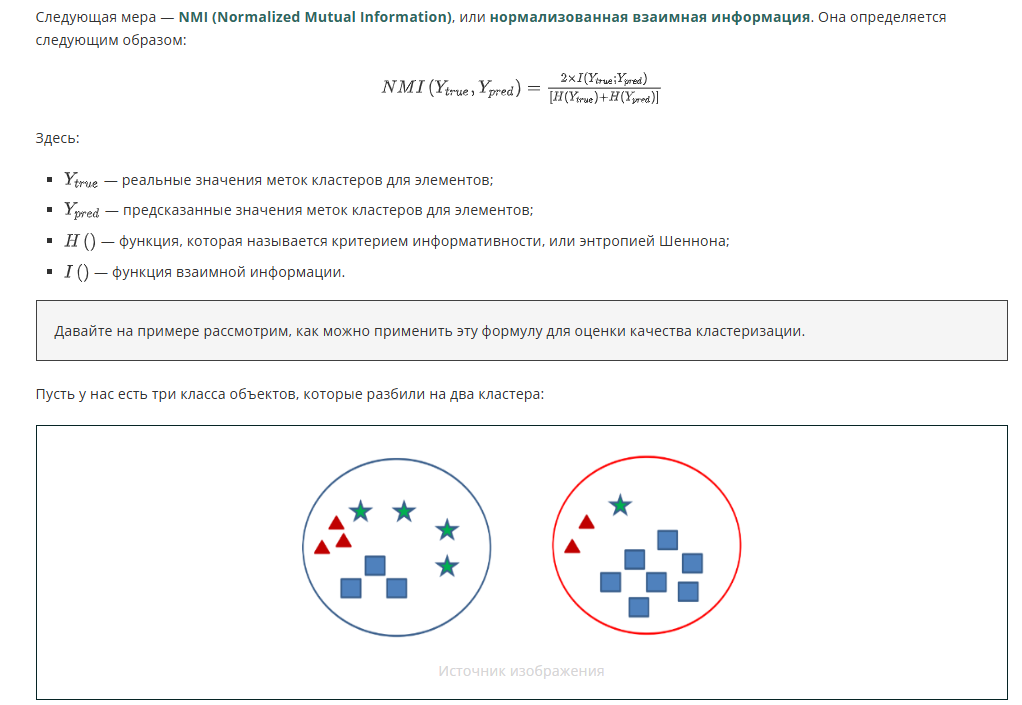

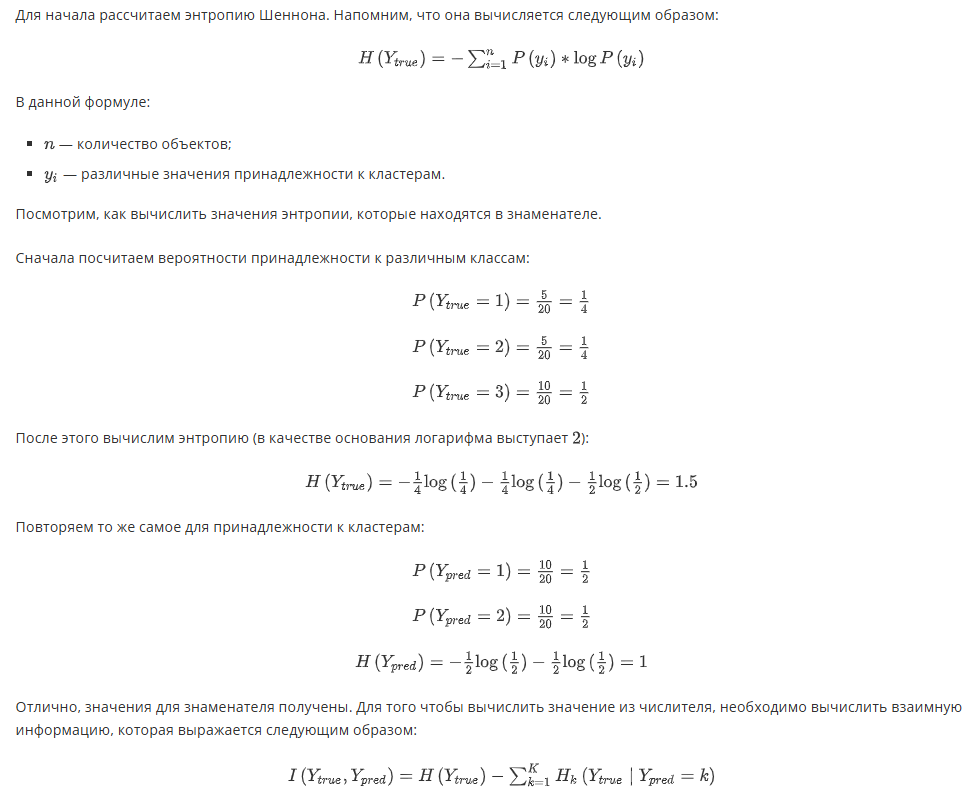

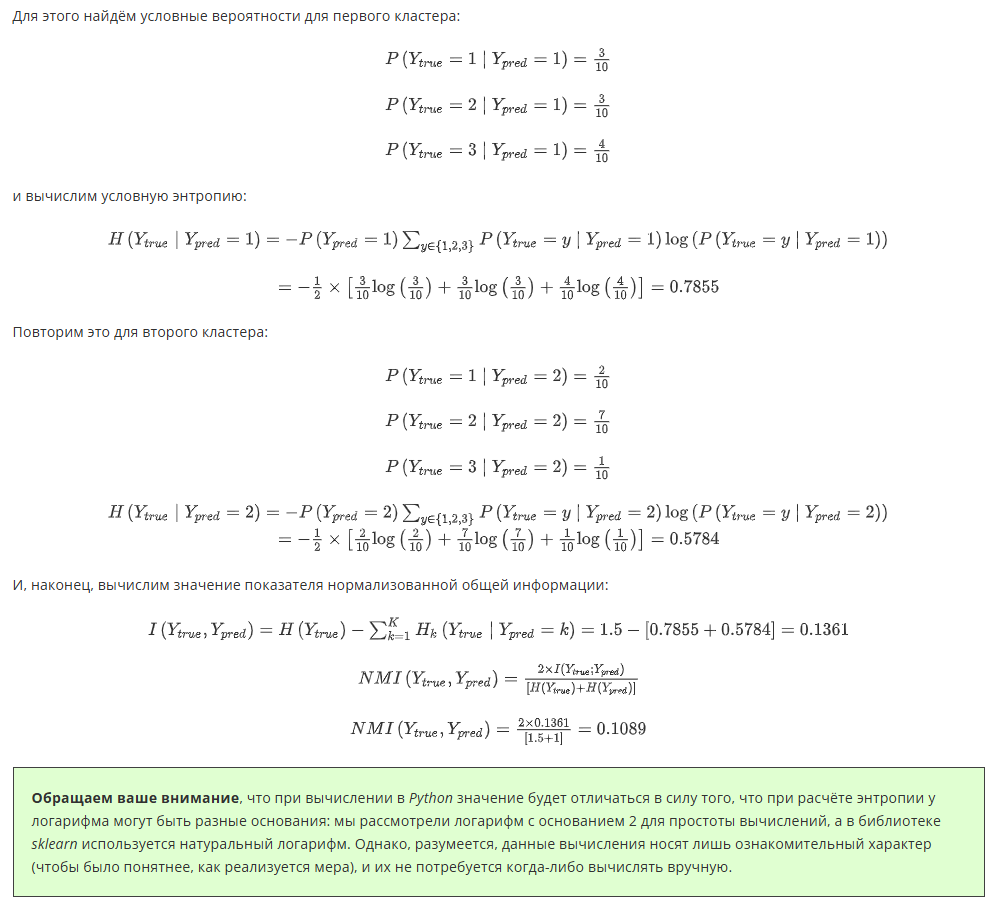

В sklearn для вычисления NMI существует метод [normalized_mutual_info_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.normalized_mutual_info_score.html#sklearn.metrics.normalized_mutual_info_score).

С точки зрения оценки качества разбиения коэффициент должен быть как можно ближе к единице: нулевое значение указывает на случайное разбиение, а 1 — на максимальную согласованность. В нашем случае значение получилось ближе к 0, но, учитывая предложенное разбиение (далёкое от необходимого), это ожидаемый результат.

## <center> **Однородность**

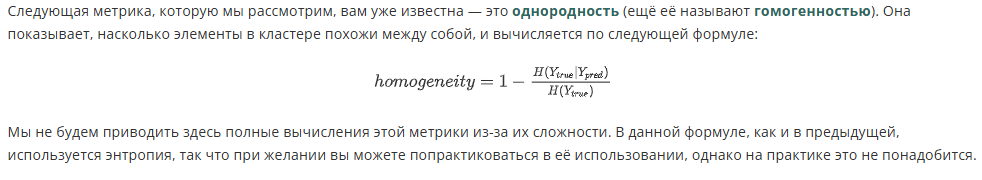

Однородность также можно вычислить, воспользовавшись методом [homogeneity_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.homogeneity_score.html) из библиотеки sklearn.

Важно, чтобы показатель гомогенности был как можно ближе к единице: это говорит о том, что в кластере находятся элементы одного и того же класса. Если он близок к нулю, это означает, что в кластере находятся элементы из разных классов.

## <center> **Полнота**

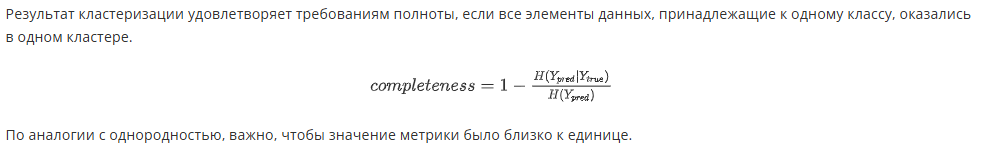

Для вычисления полноты с помощью библиотеки sklearn используется метод [completeness_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.completeness_score.html#sklearn.metrics.completeness_score).

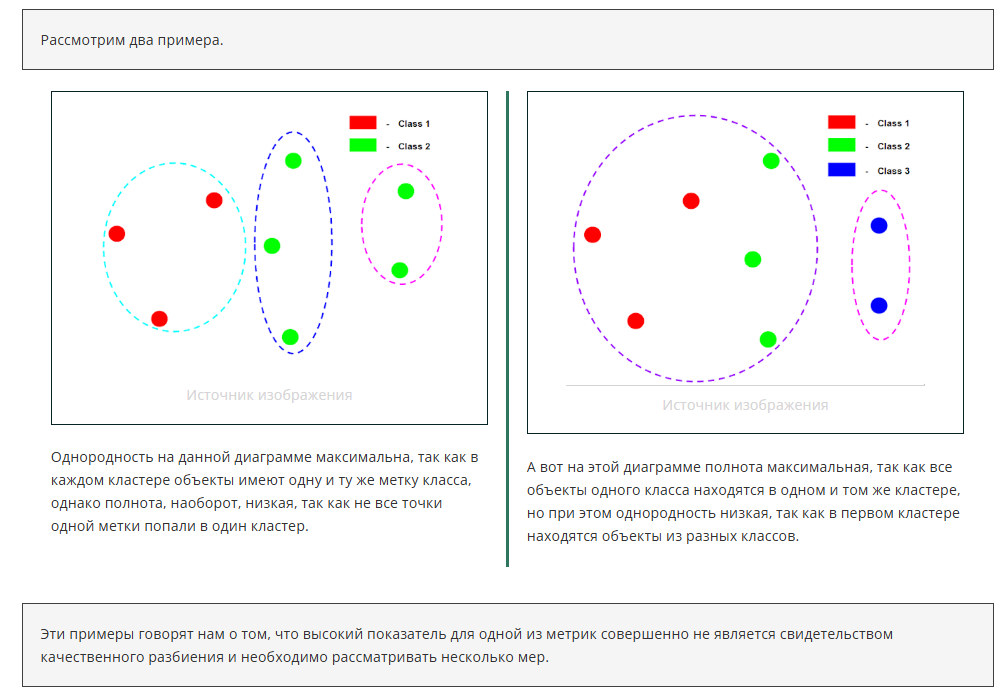

## <center> **V-мера**

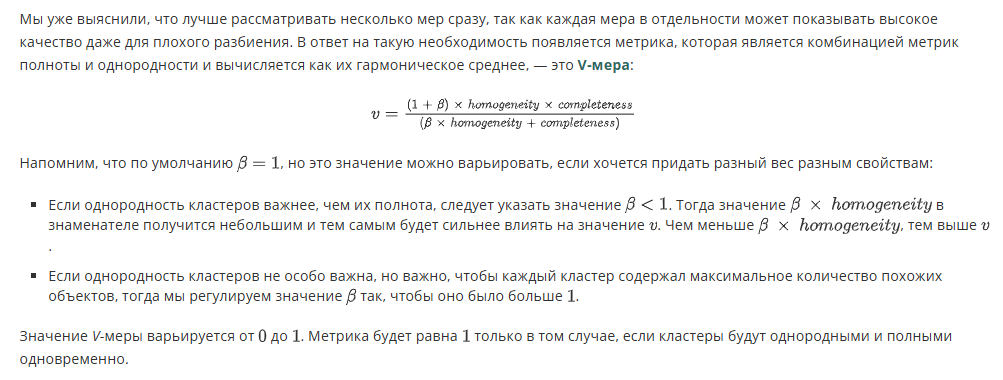

Для вычисления V-меры с помощью библиотеки sklearn используется метод [v_measure_score()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.v_measure_score.html#sklearn.metrics.v_measure_score).

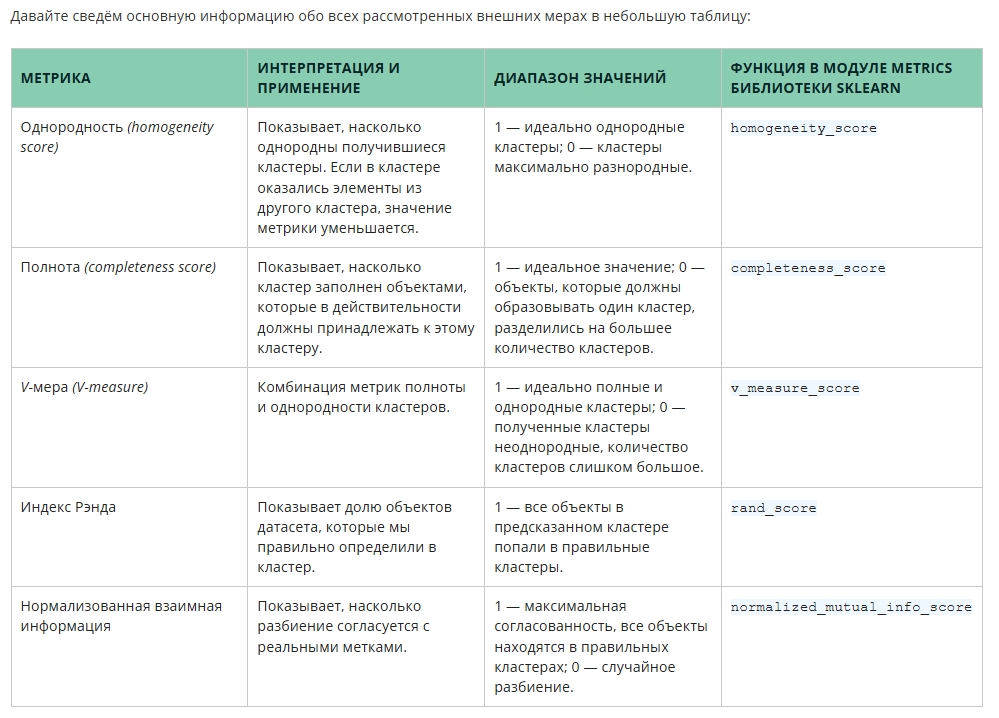

---

# <center> 4. Меры качества кластеризации. Практика

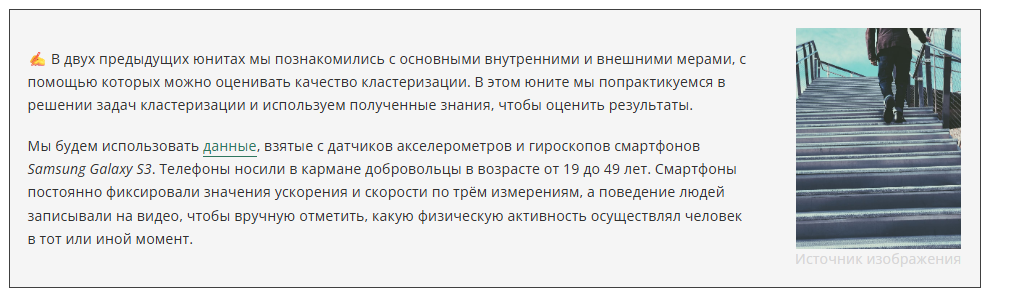

In [6]:
import pandas as pd
train_df = pd.read_csv('data/Physical Activity Data/train.txt',sep=r'\s+', engine='python')
test_df = pd.read_csv('data/Physical Activity Data/test.txt',sep=r'\s+', engine='python')
train_df.head()

,2.8858451e-001,-2.0294171e-002,-1.3290514e-001,-9.9527860e-001,-9.8311061e-001,-9.1352645e-001,-9.9511208e-001,-9.8318457e-001,-9.2352702e-001,-9.3472378e-001,...,-7.4323027e-002,-2.9867637e-001,-7.1030407e-001,-1.1275434e-001,3.0400372e-002,-4.6476139e-001,-1.8445884e-002,-8.4124676e-001,1.7994061e-001,-5.8626924e-002
0,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
1,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
2,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
3,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892
4,0.277199,-0.010098,-0.105137,-0.997335,-0.990487,-0.995420,-0.997627,-0.990218,-0.995549,-0.942469,...,0.019953,-0.545410,-0.844619,0.082632,-0.143439,0.275041,-0.368224,-0.849632,0.184823,-0.042126


In [7]:
import numpy as np
X_train = np.loadtxt("data/Physical Activity Data/train.txt")
y_train = np.loadtxt("data/Physical Activity Data/train_labels.txt")
 
X_test = np.loadtxt("data/Physical Activity Data/test.txt")
y_test = np.loadtxt("data/Physical Activity Data/test_labels.txt")
X = np.concatenate((X_train, X_test))
y = np.concatenate((y_train, y_test))
X.shape

(10299, 561)

In [11]:
len(np.unique(y))

6

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_norm = scaler.fit_transform(X)

In [13]:
print(round(X_norm[0][0],2))

0.21


In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

results = []
for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init='auto')
    labels = kmeans.fit_predict(X_norm)
    sil = silhouette_score(X_norm, labels)
    ch = calinski_harabasz_score(X_norm, labels)
    db = davies_bouldin_score(X_norm, labels)
    results.append((k, round(sil, 2), round(ch, 2), round(db, 2)))

In [15]:
results

[(2, 0.39, 7880.81, 1.07),
 (3, 0.19, 4362.14, 2.06),
 (4, 0.15, 3696.34, 2.34),
 (5, 0.13, 3027.08, 2.43),
 (6, 0.11, 2556.54, 2.38),
 (7, 0.09, 2216.56, 2.68),
 (8, 0.09, 1912.32, 2.61),
 (9, 0.1, 1717.91, 2.51)]

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import homogeneity_score, completeness_score, adjusted_rand_score
kmeans = KMeans(n_clusters=6, init='random', random_state=42)
labels = kmeans.fit_predict(X_norm)

# 3. Считаем внешние метрики
homogeneity = homogeneity_score(y, labels)          # Однородность
completeness = completeness_score(y, labels)        # Полнота
ari = adjusted_rand_score(y, labels)               # Скорректированный индекс Рэнда

# 4. Выводим с округлением до 2 знаков
print(f"Однородность: {homogeneity:.2f}")
print(f"Полнота:       {completeness:.2f}")
print(f"ARI:           {ari:.2f}")

c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Однородность: 0.54
Полнота:       0.58
ARI:           0.42


In [17]:
import pandas as pd
import numpy as np

# Словарь для понятных названий
activity_map = {
    1: 'ходьба',
    2: 'подъём',
    3: 'спуск',
    4: 'сидение',
    5: 'стояние',
    6: 'лежание'
}

# DataFrame для анализа
df_clusters = pd.DataFrame({
    'activity': y,                 # истинные метки (1–6)
    'cluster': labels              # предсказанные кластеры (0–5)
})

# Переводим номера кластеров в 1–6 для вывода
df_clusters['cluster_1based'] = df_clusters['cluster'] + 1

# Таблица: сколько наблюдений каждой активности в каждом кластере
cross = pd.crosstab(df_clusters['activity'], df_clusters['cluster_1based'])

# Для каждой активности находим кластер с наибольшим числом наблюдений
majority_cluster = cross.idxmax(axis=1)
counts_max = cross.max(axis=1)
total_per_activity = cross.sum(axis=1)
share = (counts_max / total_per_activity).round(2)

result = pd.DataFrame({
    'активность': [activity_map[a] for a in majority_cluster.index],
    'преобладающий_кластер': majority_cluster.values,
    'число_наблюдений_в_этом_кластере': counts_max.values,
    'доля_от_всей_активности': share.values
})

print(result.to_string(index=False))

активность  преобладающий_кластер  число_наблюдений_в_этом_кластере  доля_от_всей_активности
    ходьба                      3                               903                     0.52
    подъём                      3                              1242                     0.80
     спуск                      5                               889                     0.63
   сидение                      2                              1238                     0.70
   стояние                      2                              1346                     0.71
   лежание                      1                              1556                     0.80


In [18]:
kmeans = KMeans(n_clusters=2, init='random', random_state=42)
labels = kmeans.fit_predict(X_norm)

# Словарь для понятных названий
activity_map = {
    1: 'ходьба',
    2: 'подъём',
    3: 'спуск',
    4: 'сидение',
    5: 'стояние',
    6: 'лежание'
}

# DataFrame для анализа
df_clusters = pd.DataFrame({
    'activity': y,                 # истинные метки (1–6)
    'cluster': labels              # предсказанные кластеры (0–5)
})

# Переводим номера кластеров в 1–6 для вывода
df_clusters['cluster_1based'] = df_clusters['cluster'] + 1

# Таблица: сколько наблюдений каждой активности в каждом кластере
cross = pd.crosstab(df_clusters['activity'], df_clusters['cluster_1based'])

# Для каждой активности находим кластер с наибольшим числом наблюдений
majority_cluster = cross.idxmax(axis=1)
counts_max = cross.max(axis=1)
total_per_activity = cross.sum(axis=1)
share = (counts_max / total_per_activity).round(2)

result = pd.DataFrame({
    'активность': [activity_map[a] for a in majority_cluster.index],
    'преобладающий_кластер': majority_cluster.values,
    'число_наблюдений_в_этом_кластере': counts_max.values,
    'доля_от_всей_активности': share.values
})

print(result.to_string(index=False))

активность  преобладающий_кластер  число_наблюдений_в_этом_кластере  доля_от_всей_активности
    ходьба                      1                              1722                     1.00
    подъём                      1                              1536                     0.99
     спуск                      1                              1406                     1.00
   сидение                      2                              1774                     1.00
   стояние                      2                              1906                     1.00
   лежание                      2                              1932                     0.99


c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [19]:
# 3. Считаем внешние метрики
homogeneity = homogeneity_score(y, labels)          # Однородность
completeness = completeness_score(y, labels)        # Полнота
ari = adjusted_rand_score(y, labels)               # Скорректированный индекс Рэнда

# 4. Выводим с округлением до 2 знаков
print(f"Однородность: {homogeneity:.2f}")
print(f"Полнота:       {completeness:.2f}")
print(f"ARI:           {ari:.2f}")

Однородность: 0.38
Полнота:       0.98
ARI:           0.33


In [ ]:
from sklearn.cluster import AgglomerativeClustering
ag = AgglomerativeClustering(n_clusters=2)
labels = ag.fit_predict(X_norm)
completeness = completeness_score(y, labels) 
print(f"Полнота:       {completeness:.2f}")

Полнота:       1.00


---

# <center> **5. PCA**

 В этом юните мы разберём принцип решения задачи снижения размерности, а также рассмотрим один из алгоритмов, который используется для этой цели, — **PCA (Principal Component Analysis, метод главных компонент)**.

Размерность данных отражает количество содержащихся в них признаков. Если признаков очень много, можно столкнуться с **проклятием размерности**.

>**Проклятие размерности** — это проблема, связанная с экспоненциальным возрастанием объёма данных из-за увеличения размерности пространства.

Если размерность данных слишком велика, их обработка занимает чрезвычайно много времени, а их хранение требует большого объёма памяти, что, конечно, в целом затрудняет процесс работы. Поэтому количество признаков в данных необходимо уменьшить.

**Основные подходы к снижению размерности:**
* Удаление признаков

Удаление признаков может быть подходящим вариантом, когда, например, в них есть некорректные данные или так много пропусков, что эту информацию нельзя использовать для построения модели. Иногда удаляют малоинформативные признаки, которые принимают одни и те же значения или у которых очень слабая корреляция с целевой переменной. Есть и более сложные методы фильтрации — сейчас мы не будем на них останавливаться, однако обратим ваше внимание, что при удалении признаков мы практически всегда теряем какую-то информацию о данных.
* Извлечение новых признаков с помощью специальных алгоритмов: 

Создание новых признаков не даёт потерять важную информацию. Допустим, в нашем наборе данных есть 100 признаков. При извлечении признаков мы отказываемся от старых и создаём 100 новых независимых (таких, между которыми коэффициент корреляции равен нулю). Каждый новый признак представляет собой комбинацию старых. Независимые новые признаки определяются специальным алгоритмом (например, PCA) и упорядочиваются  по тому, насколько хорошо они сохраняют информацию о данных. После этого можно отбросить наименее важные новые признаки в зависимости от того, какую объяснённую дисперсию необходимо сохранить: допустим, первые 80 признаков из извлечённых 100 объясняют 95 % дисперсии и нас устраивает такой процент. Значит, мы отбрасываем последние 20 новых признаков.

В результате множества исследований было выявлено, что такое отбрасывание части новых признаков совершенно не мешает получать модели машинного обучения, которые будут показывать высокую эффективность. Например, для распознавания лиц достаточно использовать лишь треть извлечённых из фотографий признаков, а для обнаружения лактозы в безлактозном молоке NIR-спектроскопией будет достаточно извлечь с помощью PCA всего лишь два признака из 601.

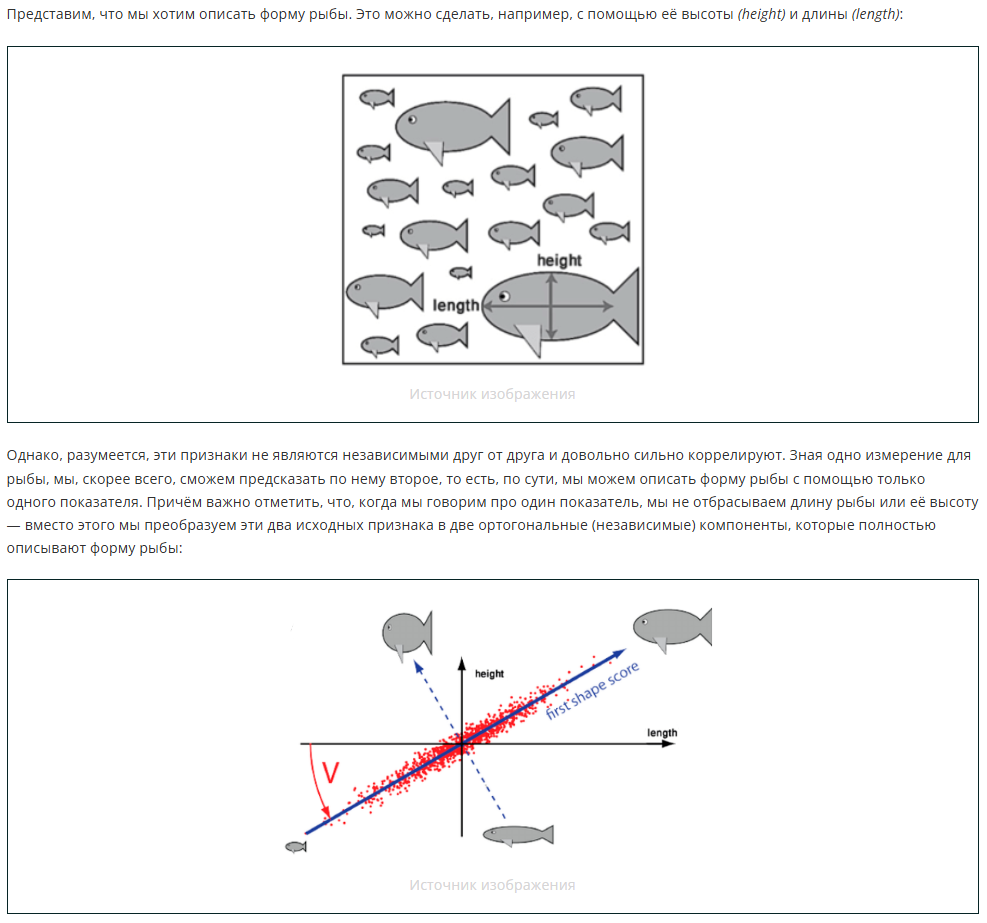

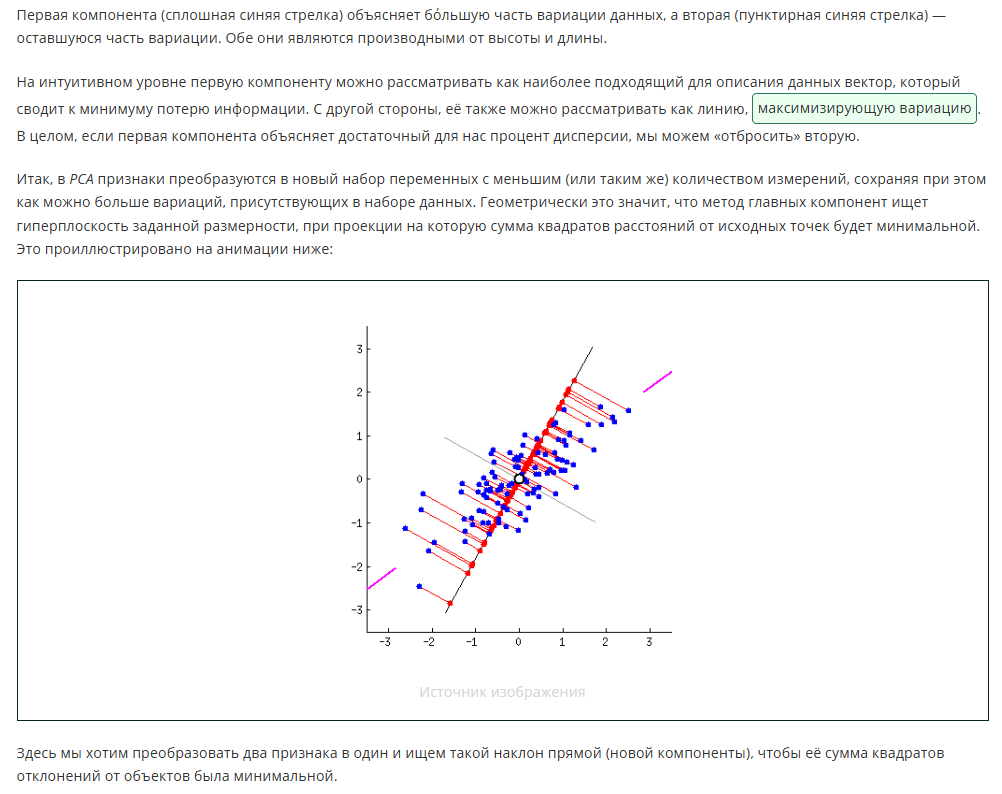

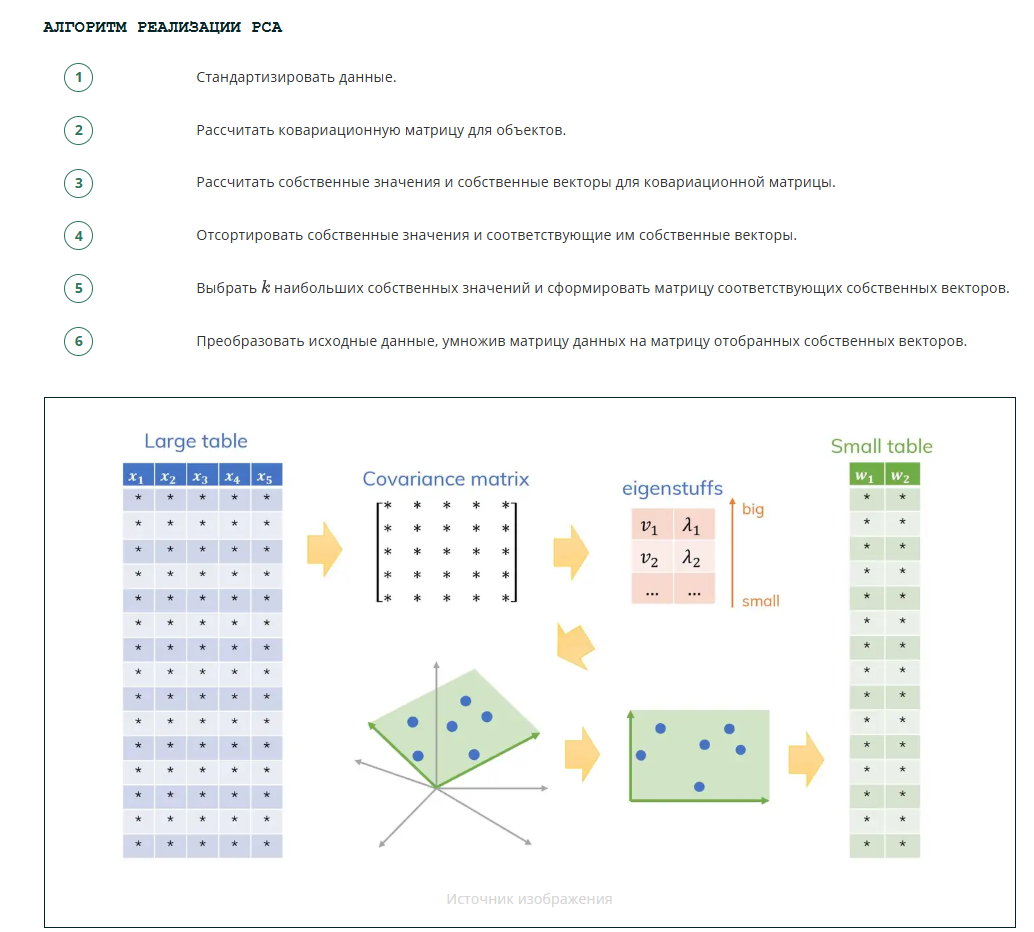

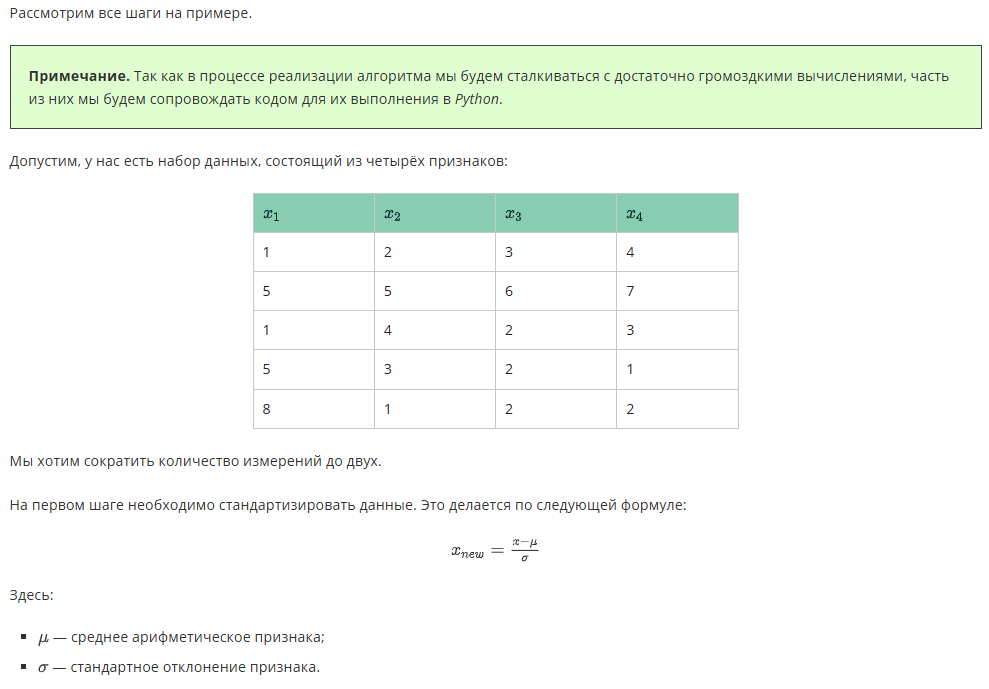

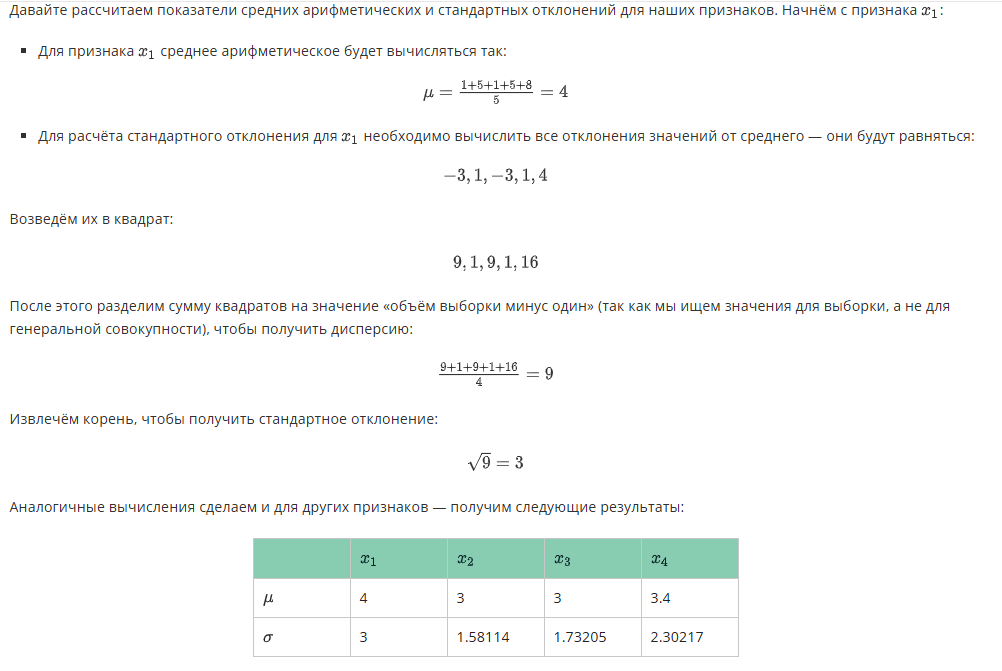

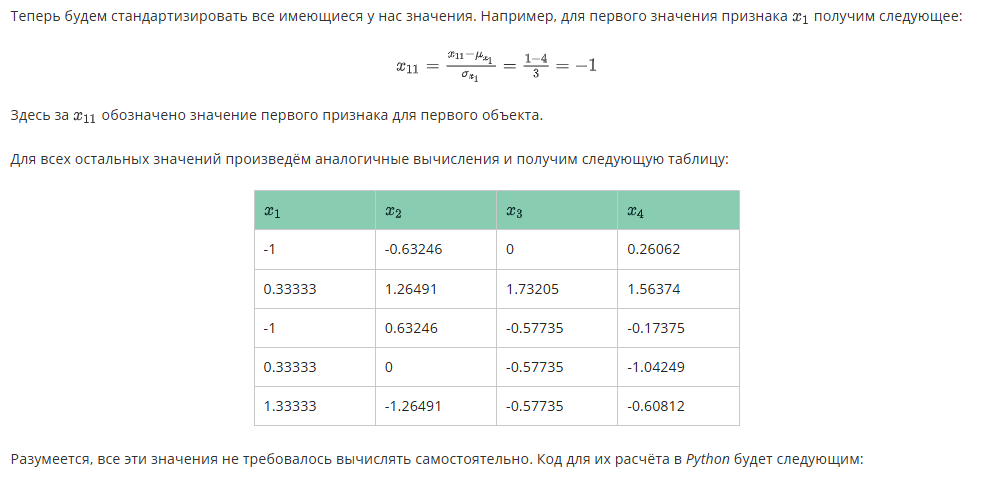

In [21]:
import numpy as np
import pandas as pd
A = np.matrix([[1,2,3,4],
               [5,5,6,7],
               [1,4,2,3],
               [5,3,2,1],
               [8,1,2,2]])

df = pd.DataFrame(A,columns  = ['x1','x2','x3','x4'])
df_std  = (df - df.mean()) / (df.std())

In [22]:
df_std

,x1,x2,x3,x4
0,-1.000000,-0.632456,0.000000,0.260623
1,0.333333,1.264911,1.732051,1.563740
2,-1.000000,0.632456,-0.577350,-0.173749
3,0.333333,0.000000,-0.577350,-1.042493
4,1.333333,-1.264911,-0.577350,-0.608121


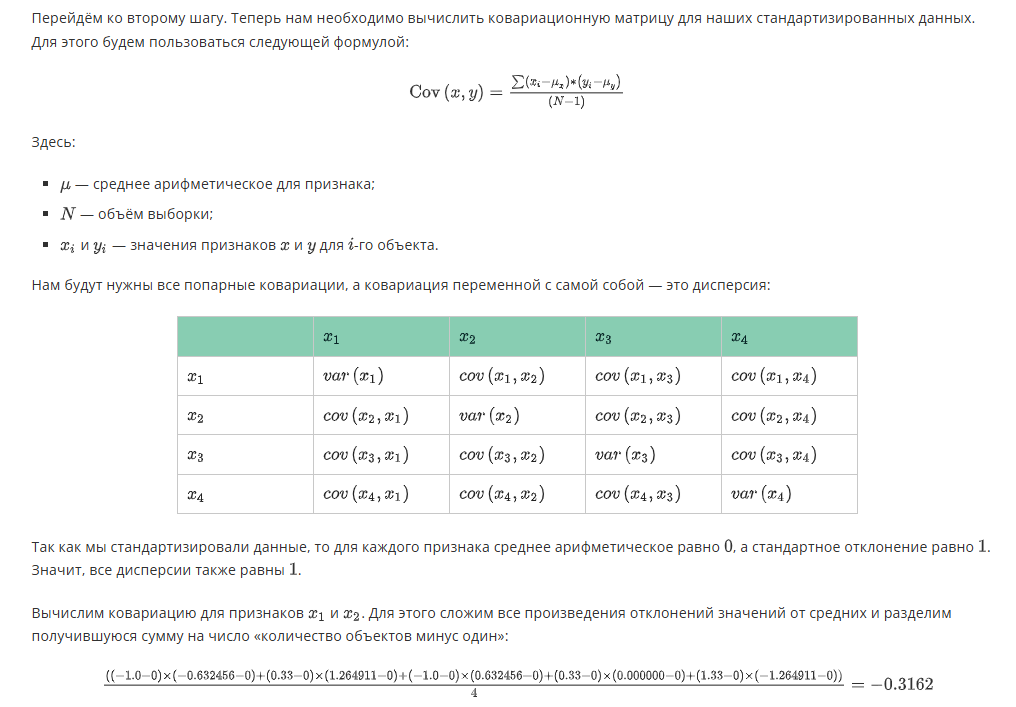

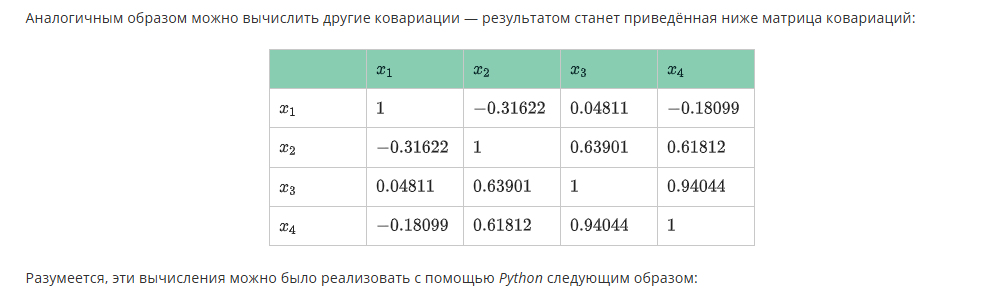

In [23]:
cov_mat = np.cov(df_std.T)
cov_mat

array([[ 1.        , -0.31622777,  0.04811252, -0.18098843],
       [-0.31622777,  1.        ,  0.63900965,  0.61812254],
       [ 0.04811252,  0.63900965,  1.        ,  0.94044349],
       [-0.18098843,  0.61812254,  0.94044349,  1.        ]])

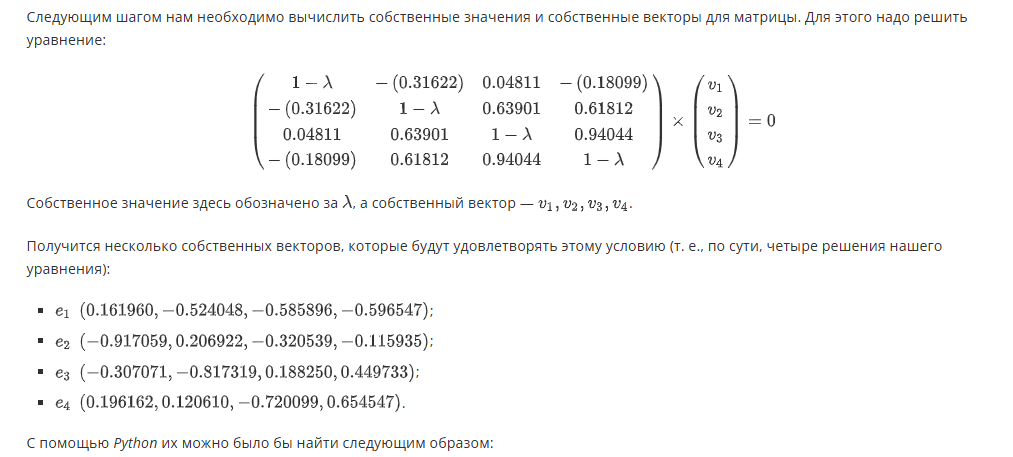

In [24]:
eigen_val, eigen_vectors = np.linalg.eig(cov_mat)

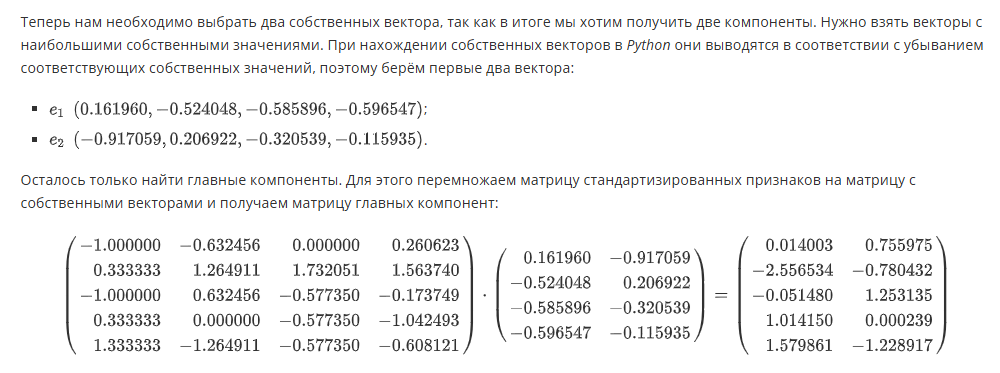

Таким образом, мы получили две главных компоненты. Можно проверить, получили ли бы мы тот же результат, если бы воспользовались сразу готовым алгоритмом на Python — [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

В параметр ```n_components``` в качестве значения можно передать количество необходимых компонентов или минимально допустимую объяснённую дисперсию в виде десятичной дроби. Например, если нам нужно столько компонент, чтобы они объясняли не менее 90 % разброса данных, то мы запишем ```n_components``` = 0.9.

In [25]:
#импортируем нужный алгоритм

from sklearn.decomposition import PCA
#определяем метод главных компонент с двумя компонентами
pca = PCA(n_components=2)
#обучаем алгоритм на наших данных
principalComponents = pca.fit_transform(df_std)

In [26]:
principalComponents

array([[-1.40033078e-02,  7.55974765e-01],
       [ 2.55653399e+00, -7.80431775e-01],
       [ 5.14801919e-02,  1.25313470e+00],
       [-1.01415002e+00,  2.38808310e-04],
       [-1.57986086e+00, -1.22891650e+00]])

Мы получили ровно такие же результаты. Разумеется, в будущем при решении практических задач вы сможете сразу использовать алгоритм PCA, не реализуя вручную всю последовательность действий.

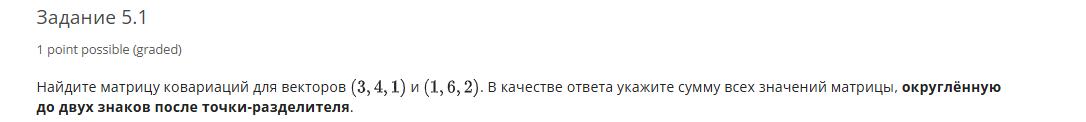

In [31]:
import numpy as np
A = np.matrix([[3,4,1],
               [1,6,2],
               ])
A_norm = (A - A.mean())
cov_mat = np.cov(A_norm)
print(round(cov_mat.sum().sum(),2))

14.33


In [32]:
A = np.matrix([[8,7,2,9],
               [1,3,6,3],
               [7,2,0,3],
               [10,3,1,1],
               [8,1,3,4]])
df = pd.DataFrame(A,columns  = ['x1','x2','x3','x4'])
df_std  = (df - df.mean()) / (df.std())
from sklearn.decomposition import PCA
#определяем метод главных компонент с двумя компонентами
pca = PCA(n_components=0.9)
#обучаем алгоритм на наших данных
principalComponents = pca.fit_transform(df_std)
principalComponents

array([[-1.61145254,  1.76368007,  0.01320928],
       [ 2.08441051,  1.01724955, -0.24417084],
       [-0.29568142, -0.95946326, -0.05272576],
       [-0.50390826, -1.24373821, -0.50808763],
       [ 0.3266317 , -0.57772816,  0.79177495]])

---

## <center> 6. Снижение размерности: SVD и t-SNE

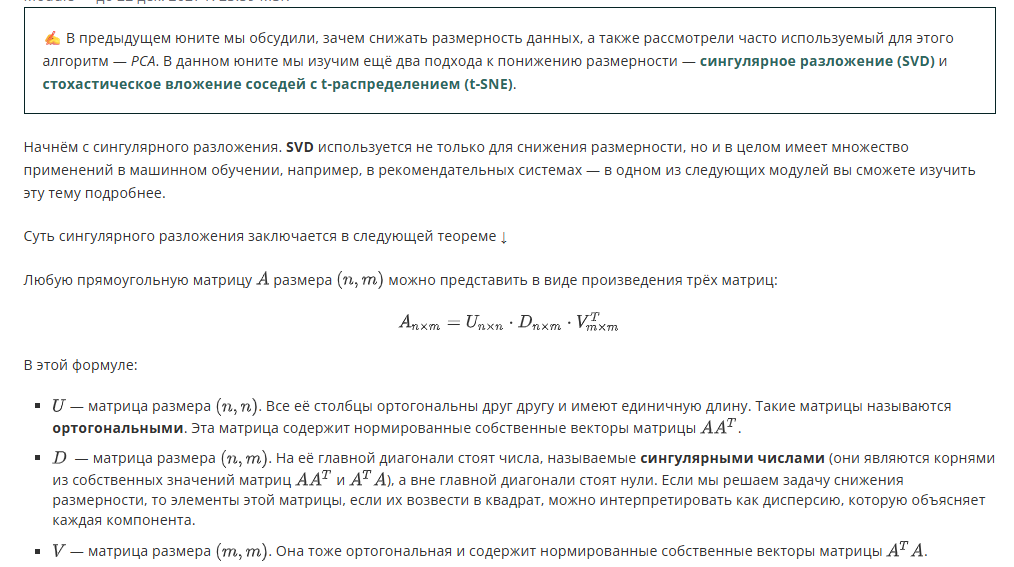

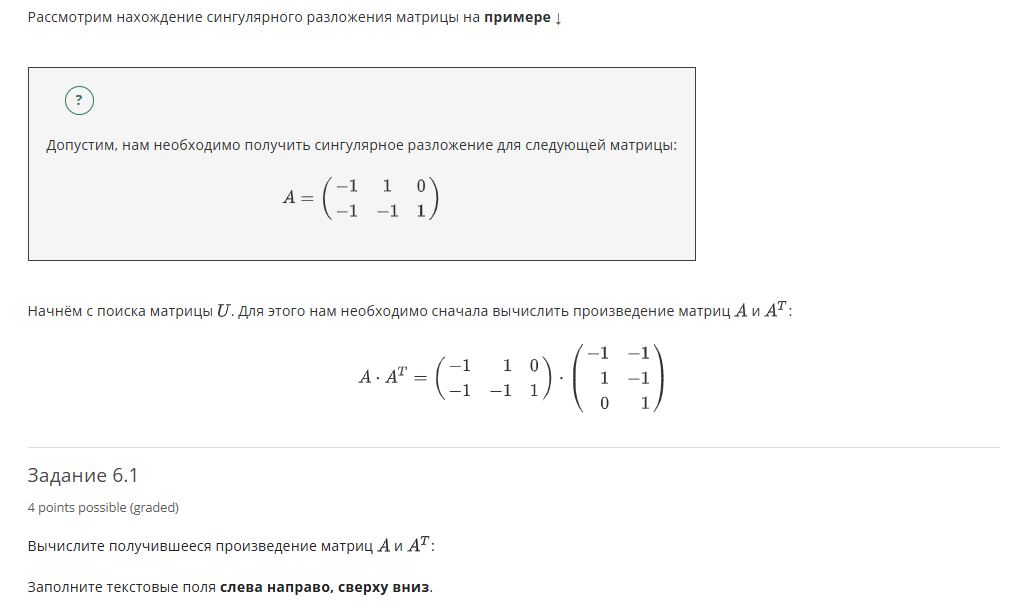

In [1]:
import numpy as np
A = np.matrix([[-1,1,0],
              [-1,-1,1]])
U = A @ A.T
U

matrix([[2, 0],
        [0, 3]])

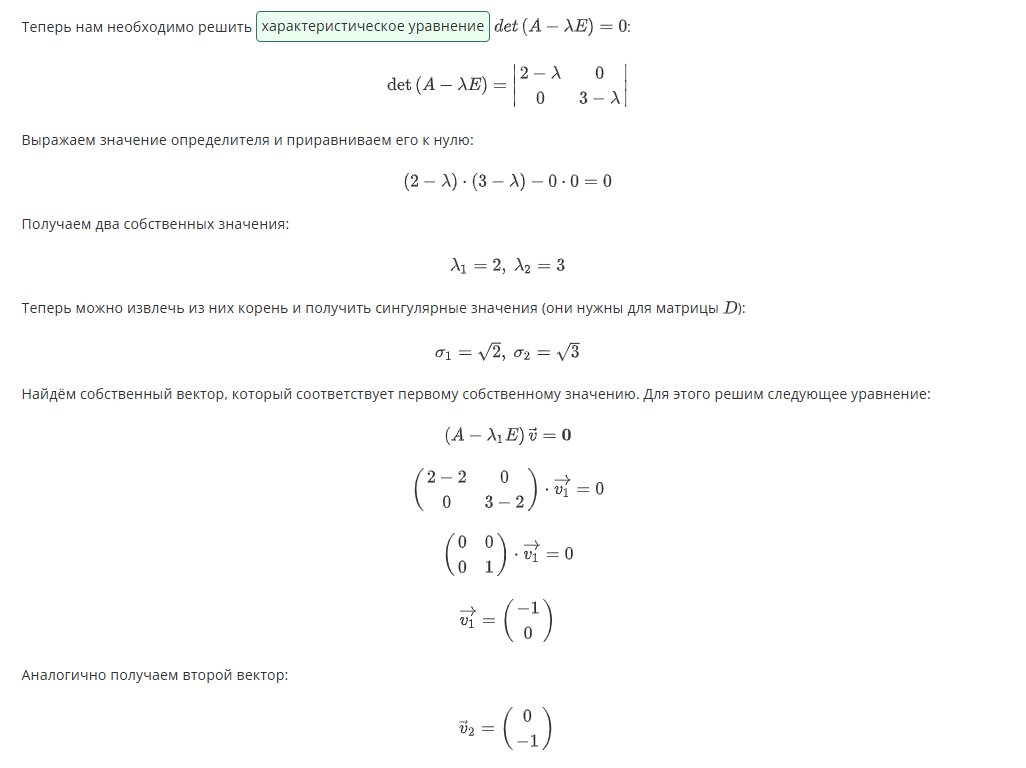

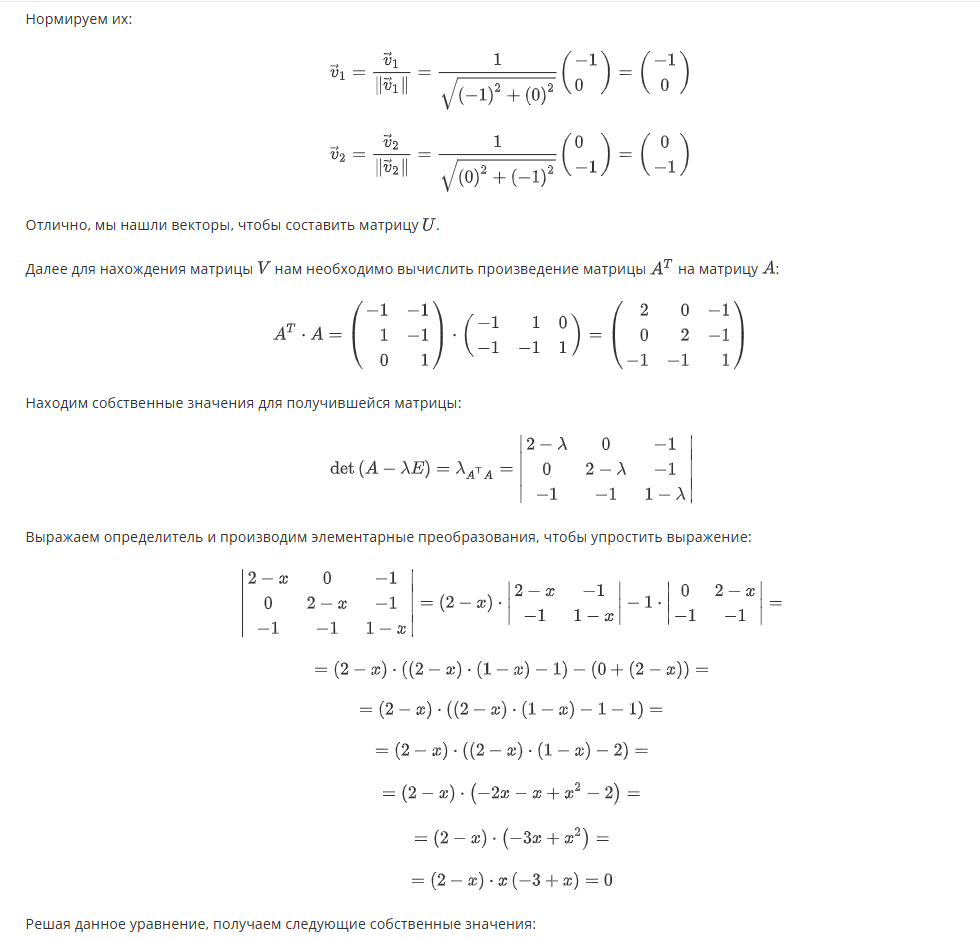

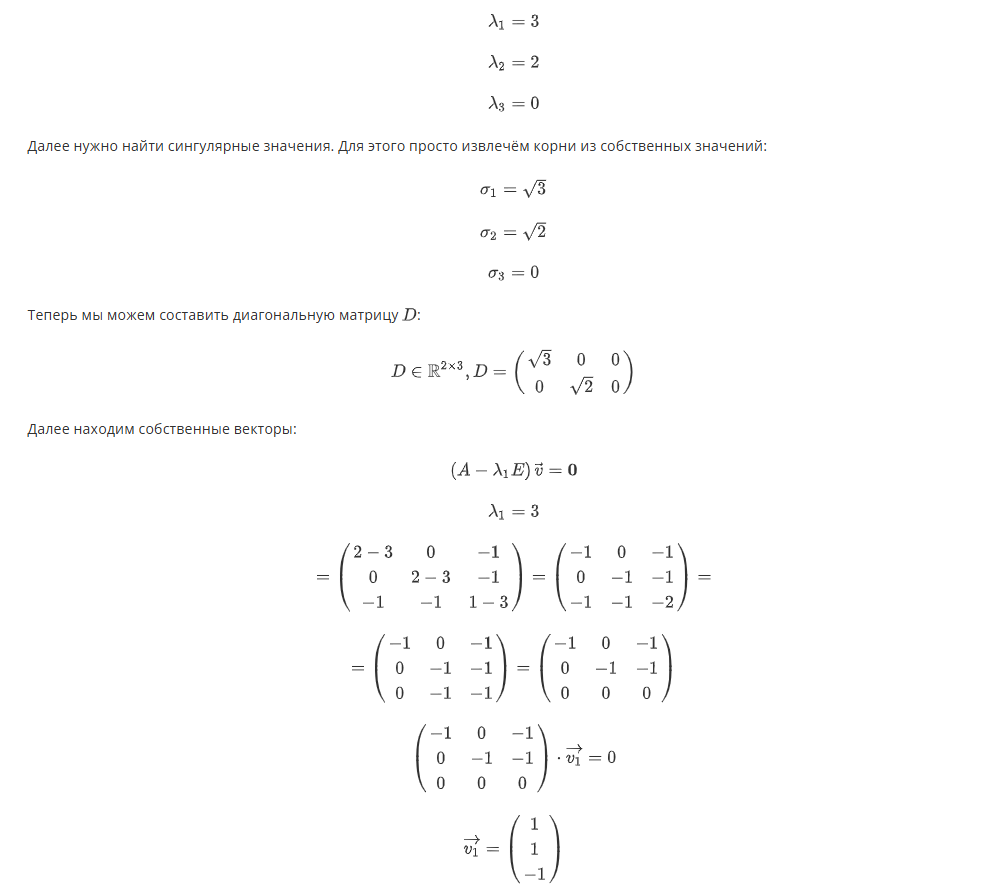

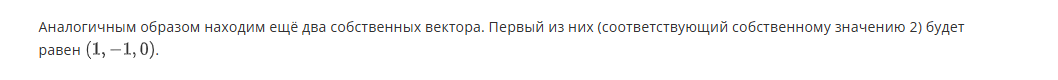

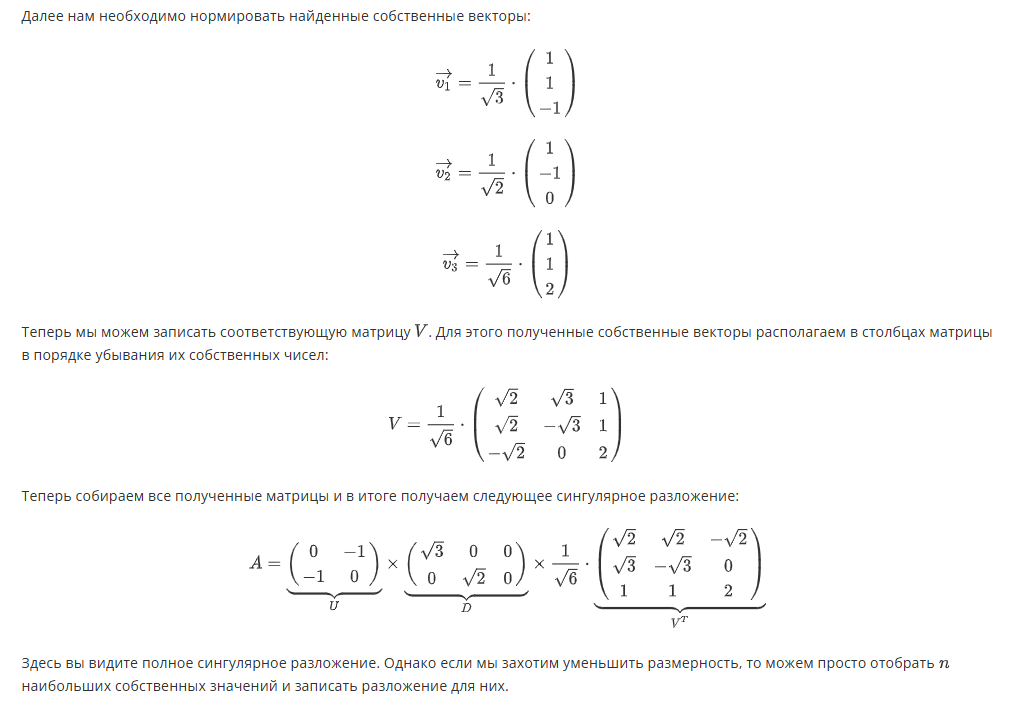

Для того чтобы реализовать сингулярное разложение с помощью библиотеки sklearn, необходимо использовать алгоритм [TruncatedSVD()](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html), в который передаётся ```n_components``` в качестве параметра, определяющего количество итоговых компонент:

```python
# создаём объект класса TruncatedSVD
# n_components — размерность нового пространства, n_iter — количество итераций
svd = TruncatedSVD(n_components=5, n_iter=7, random_state=42)
# обучаем модель на данных X
svd.fit(X)
# применяем уменьшение размерности к матрице X
transformed = svd.transform(X)
```

---

## <center> t-SNE (стохастическое вложение соседей с t-распределением)

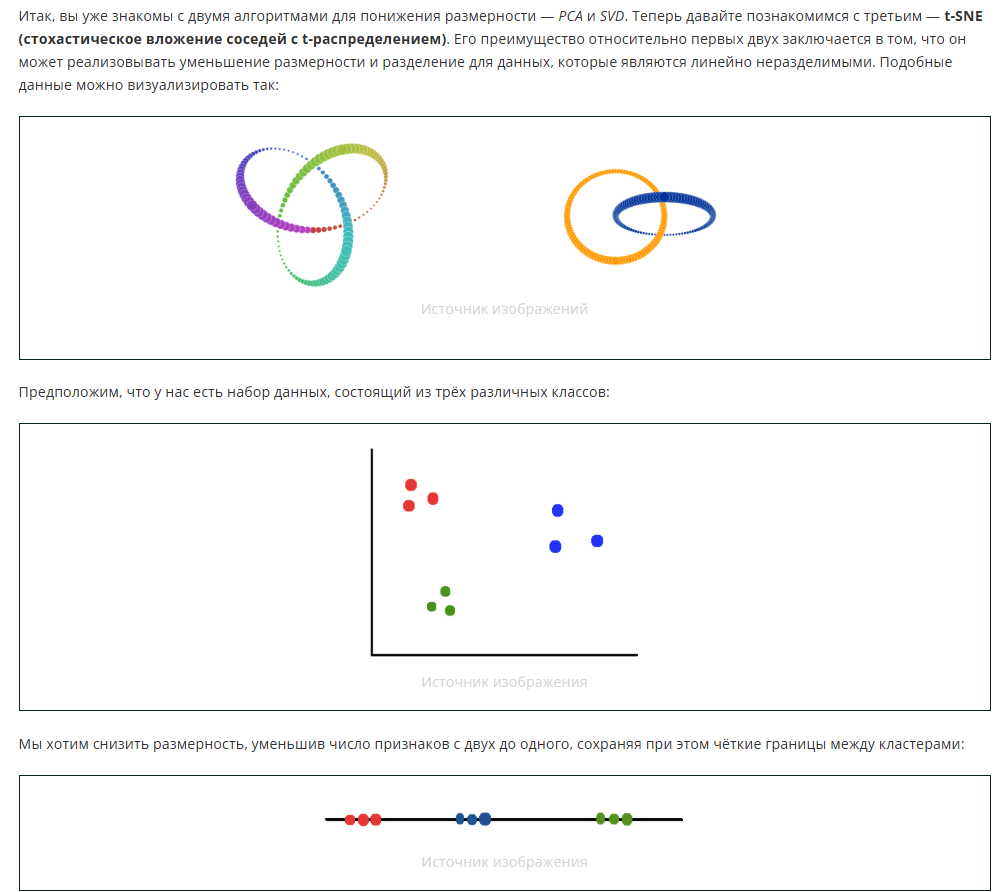

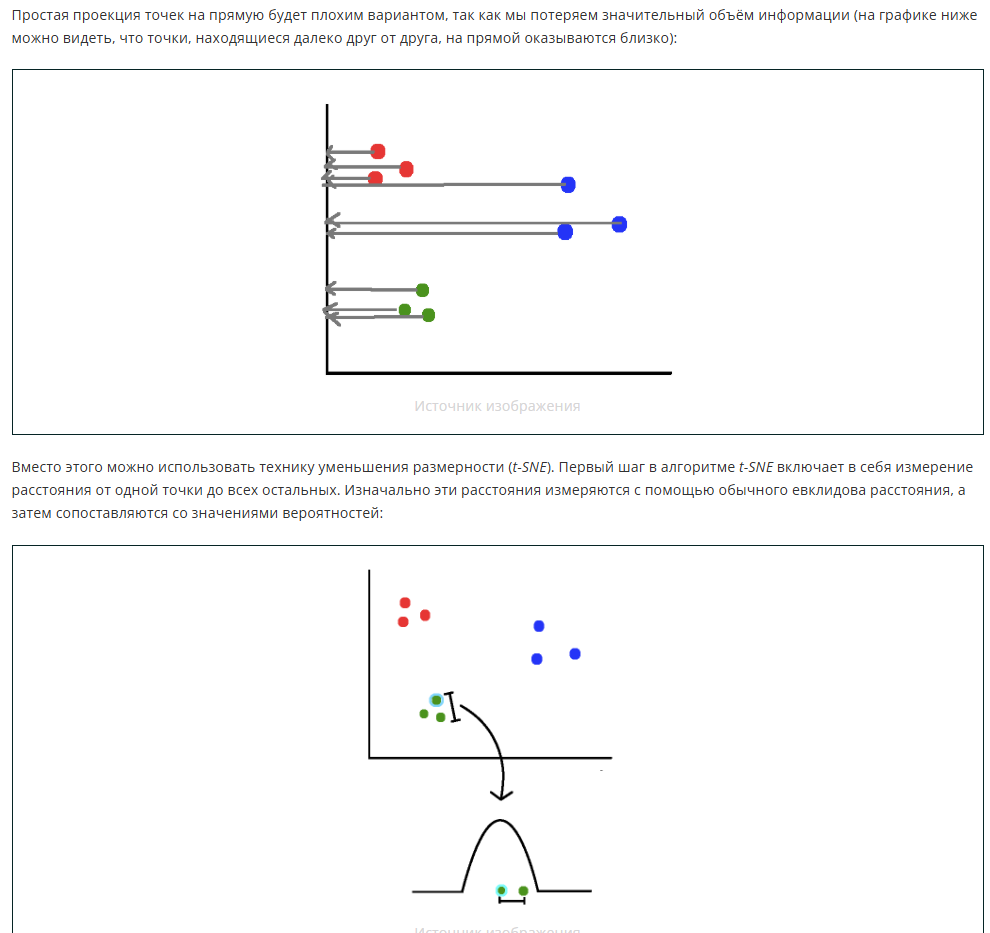

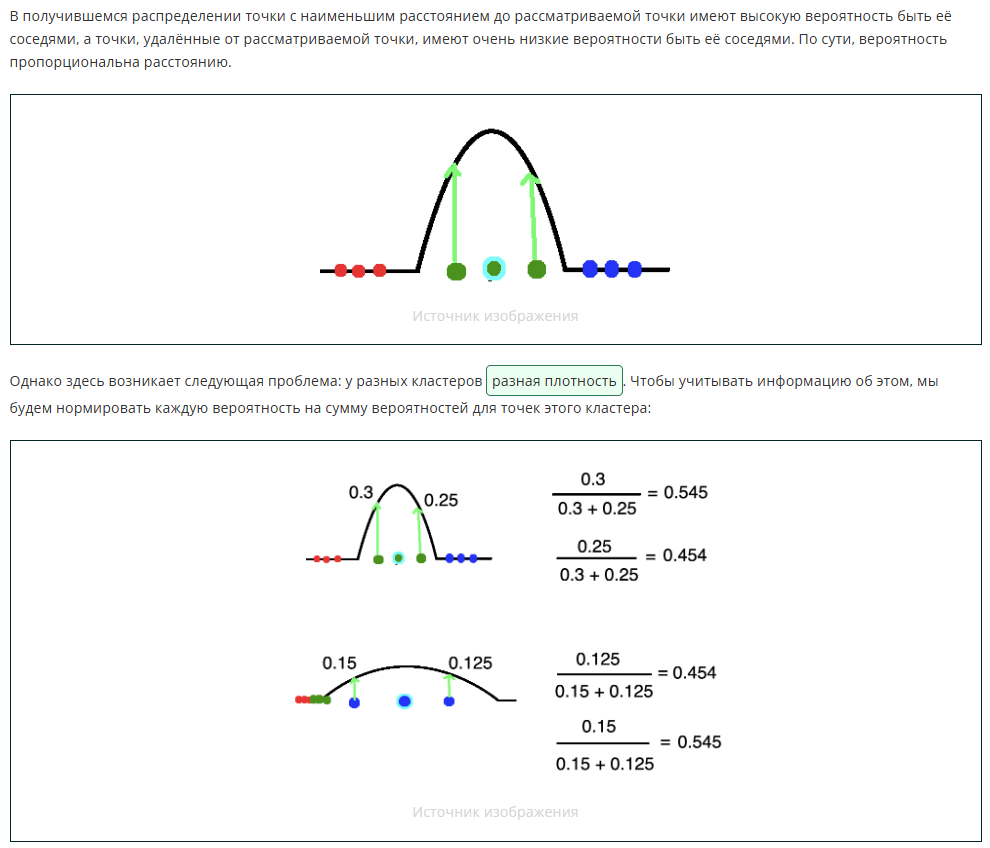

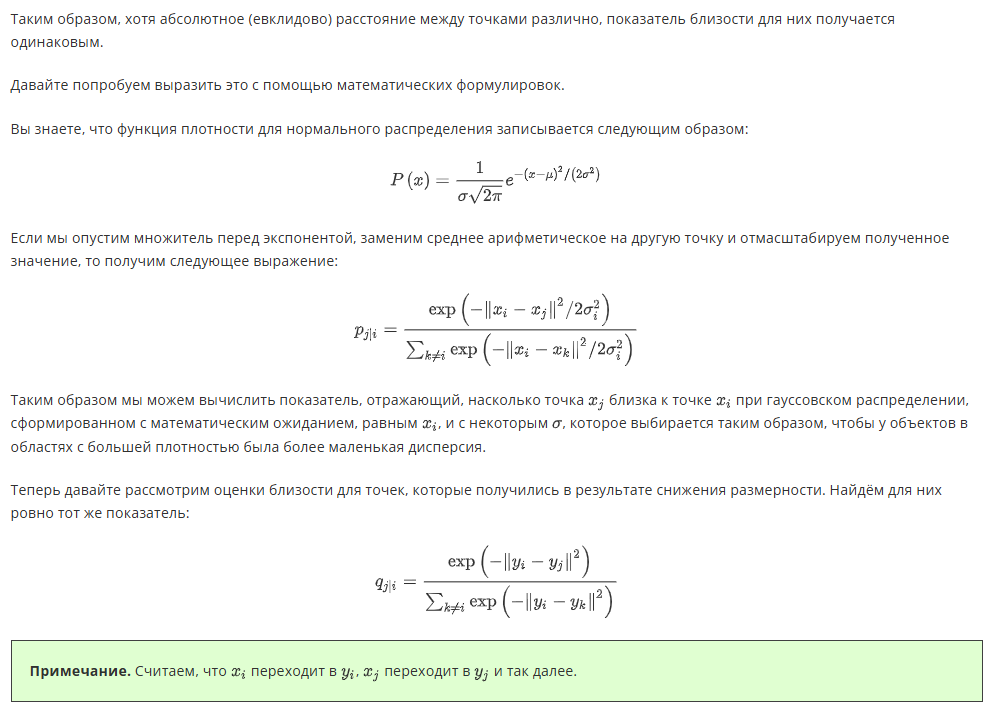

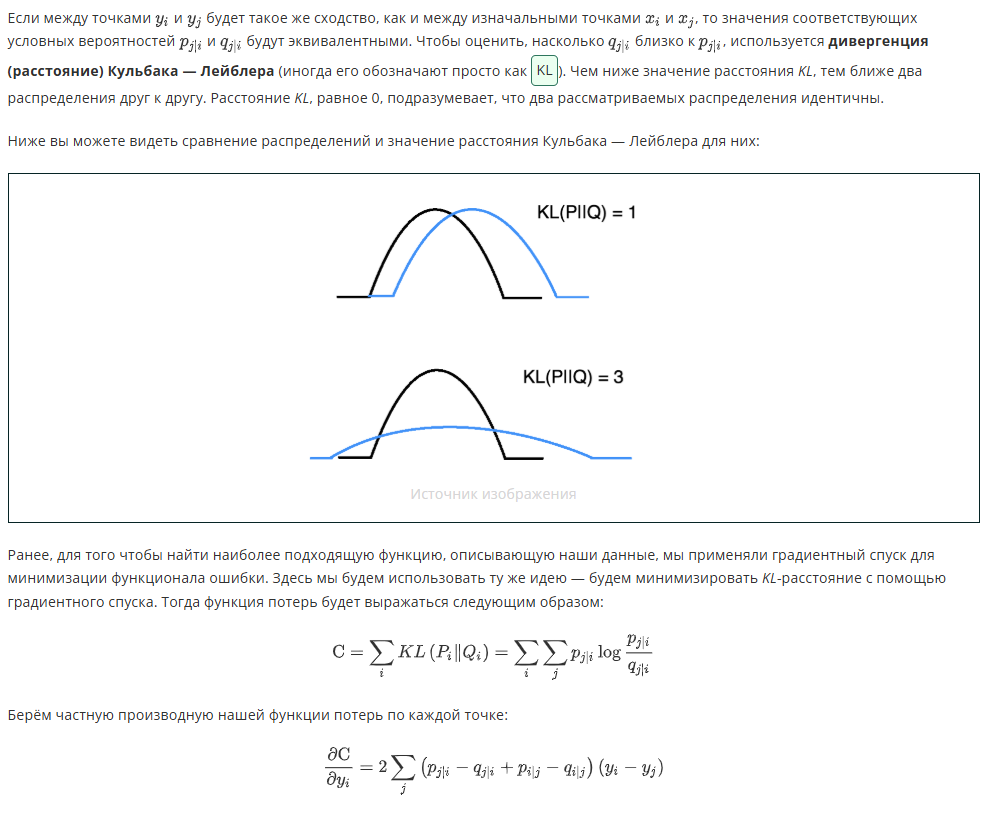

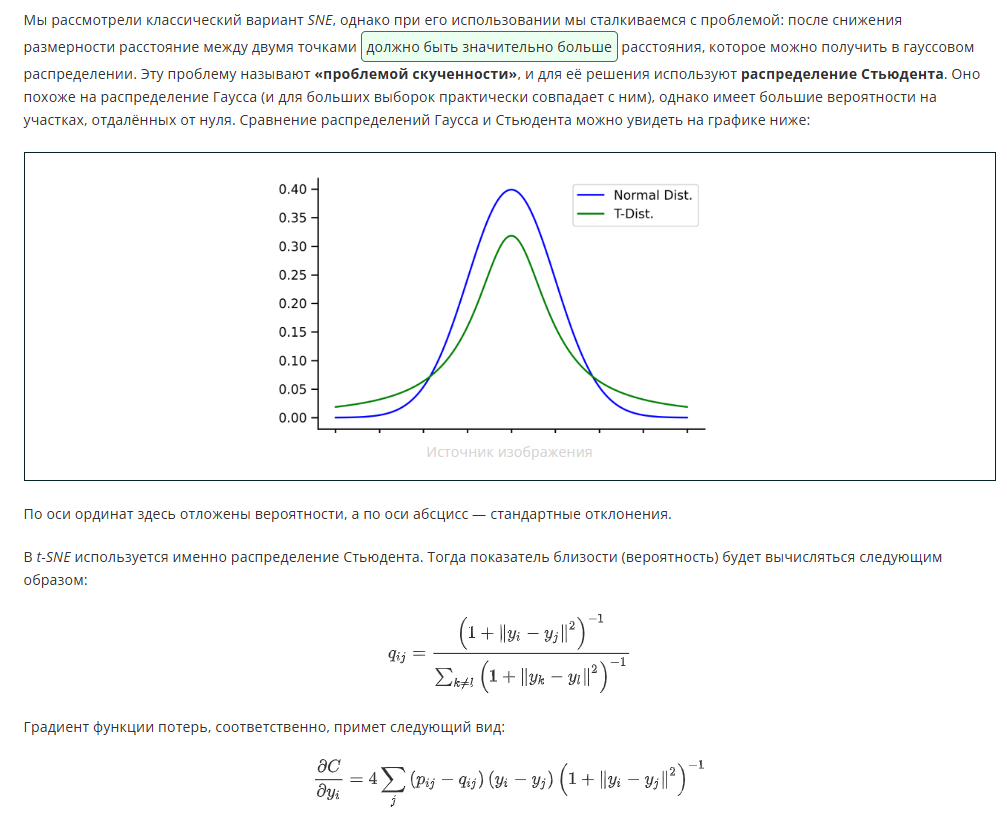

Для реализации t-SNE в sklearn понадобится алгоритм [TSNE()](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html):

```python
# импортируем класс TSNE из модуля manifold библиотеки sklearn
from sklearn.manifold import TSNE
# создаём объект класса TSNE
# n_components — размерность нового пространства
tsne = TSNE(n_components=2, perplexity=30, n_iter=500, random_state=42)
# обучаем модель на данных X и применяем к матрице X уменьшение размерности
tsne.fit_transform(X)
```

---

# <center>  7. Снижение размерности. Практика

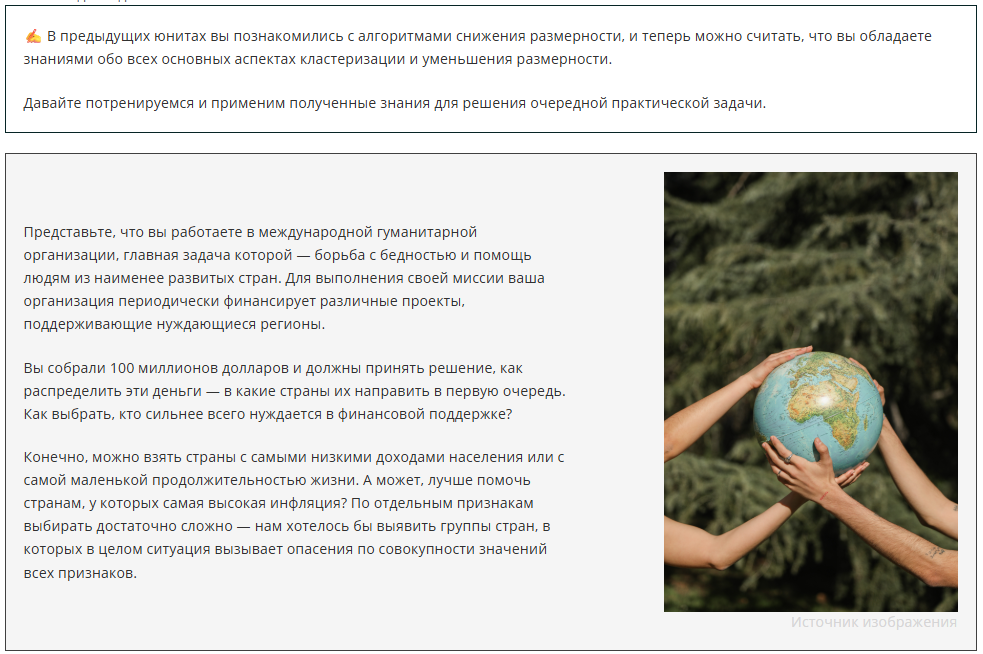

Для решения этой задачи мы как раз и используем наши навыки в снижении размерности и кластеризации данных: попробуем выделить кластеры стран, схожих по своим характеристикам, и среди них выявить кластер особо нуждающихся.

Данные содержат следующие признаки:
* country — название страны;
* child_mort — показатель смертности детей до 5 лет;
* exports — показатель экспорта на душу населения;
* health — показатель затрат на здравоохранение на душу населения;
* imports — показатель импорта на душу населения;
* Income — средний доход на душу населения;
* Inflation — годовой показатель инфляции;
* life_expec — средняя продолжительность жизни;
* total_fer — суммарный коэффициент рождаемости;
* gdpp — значение ВВП на душу населения.

In [6]:
import pandas as pd
df = pd.read_csv('data/Country-data.zip', compression='zip')
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [7]:
print(f"Максимальное значение средней продолжительности жизни - {round(df['life_expec'].max(),1)}")

Максимальное значение средней продолжительности жизни - 82.8


In [8]:
from sklearn.preprocessing import StandardScaler
X_norm = StandardScaler().fit_transform(df.select_dtypes(include=['float', 'int']))
print(round(X_norm[0][0],2))

1.29


In [15]:
num_cols = df.select_dtypes(include=['float', 'int']).columns
X_norm = pd.DataFrame(StandardScaler().fit_transform(df[num_cols]), columns=num_cols)
corr = X_norm.corr()
corr

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
child_mort,1.000000,-0.318093,-0.200402,-0.127211,-0.524315,0.288276,-0.886676,0.848478,-0.483032
exports,-0.318093,1.000000,-0.114408,0.737381,0.516784,-0.107294,0.316313,-0.320011,0.418725
health,-0.200402,-0.114408,1.000000,0.095717,0.129579,-0.255376,0.210692,-0.196674,0.345966
imports,-0.127211,0.737381,0.095717,1.000000,0.122406,-0.246994,0.054391,-0.159048,0.115498
income,-0.524315,0.516784,0.129579,0.122406,1.000000,-0.147756,0.611962,-0.501840,0.895571
inflation,0.288276,-0.107294,-0.255376,-0.246994,-0.147756,1.000000,-0.239705,0.316921,-0.221631
life_expec,-0.886676,0.316313,0.210692,0.054391,0.611962,-0.239705,1.000000,-0.760875,0.600089
total_fer,0.848478,-0.320011,-0.196674,-0.159048,-0.501840,0.316921,-0.760875,1.000000,-0.454910
gdpp,-0.483032,0.418725,0.345966,0.115498,0.895571,-0.221631,0.600089,-0.454910,1.000000


In [20]:
max_corr = -1
for elem in corr.values.flatten():
    if elem == 1:
        continue
    elif elem > max_corr:
        max_corr =  elem
print(round(max_corr,2)) 

0.9


In [22]:
from sklearn.decomposition import PCA
#определяем метод главных компонент с двумя компонентами
pca = PCA(n_components=0.9)
#обучаем алгоритм на наших данных
principalComponents = pca.fit_transform(X_norm)

# Сколько компонент взяли
n_components_used = pca.n_components_
print(f"Минимальное число компонент для ≥90% дисперсии: {n_components_used}")

# Доля объяснённой дисперсии каждой компонентой
explained_var = pca.explained_variance_ratio_
print("Доля дисперсии по компонентам:", explained_var)

# Суммарная доля (должна быть >= 0.9)
cumulative_var = explained_var.cumsum()
print("Накопленная доля дисперсии:", cumulative_var)

Минимальное число компонент для ≥90% дисперсии: 5
Доля дисперсии по компонентам: [0.4595174  0.17181626 0.13004259 0.11053162 0.07340211]
Накопленная доля дисперсии: [0.4595174  0.63133365 0.76137624 0.87190786 0.94530998]


In [23]:
print(round(explained_var[0],2))

0.46


In [27]:
# corr_matrix — матрица корреляций компонент (DataFrame)
corr_matrix = pd.DataFrame(principalComponents).corr()

# Маска: исключаем диагональ (где i == j)
mask = ~np.eye(corr_matrix.shape[0], dtype=bool)

# Берём только внедиагональные элементы
off_diag_values = corr_matrix.values[mask]

# Задаём порог (например, |r| > 0.1 — уже «заметная» корреляция)
threshold = 0.001
count_above_threshold = np.sum(np.abs(off_diag_values) > threshold)

print(f"Число внедиагональных корреляций с |r| > {threshold}: {count_above_threshold}")
print("Внедиагональные корреляции (первые 10):", off_diag_values[:10])

Число внедиагональных корреляций с |r| > 0.001: 0
Внедиагональные корреляции (первые 10): [-1.20927751e-16 -6.28522459e-17 -1.11438671e-16 -3.57961230e-17
 -1.20927751e-16  1.22924771e-16 -5.70854550e-17 -1.10503013e-16
 -6.28522459e-17  1.22924771e-16]


<Axes: xlabel='cluster', ylabel='silhouette'>

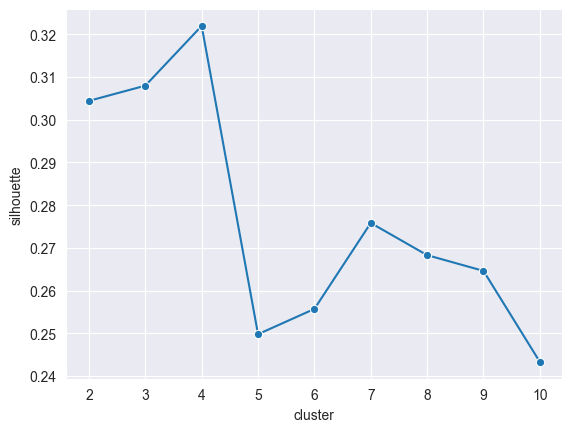

In [29]:
from sklearn.cluster import KMeans
# импортируем метрику силуэта
from sklearn.metrics import silhouette_score
import seaborn as sns
# напишем функцию, как и при подсчете метода локтя
def get_silhouette(cluster_num, X):
    k_means =  KMeans(n_clusters=cluster_num, init='k-means++', n_init=10, random_state=1)
    k_means.fit(X)
# подсчитаем метрику силуэта, передав данные и то, к каким кластерам относятся объекты
    silhouette = silhouette_score(X, k_means.predict(X))
    return silhouette

# создадим пустой словарь, ключами будут инерция и количество кластеров
silhouette_res = {"silhouette": [], "cluster": []}

# выберем нужные данные 
X = principalComponents

for cluster_num in range(2, 11):
    silhouette_res["silhouette"].append(get_silhouette(cluster_num, X))
    silhouette_res["cluster"].append(cluster_num)
    
# сохраним в датафрейм значение силуэта и количество кластеров
silhouette_df = pd.DataFrame(silhouette_res)

# установим стиль для визуализиции
sns.set_style("darkgrid")
# визуализируем зависимость значения инерции от количества кластеров
sns.lineplot(data=silhouette_df, x="cluster", y="silhouette", marker= "o")

In [30]:
k_means =  KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=1)
k_means.fit(X)
labels = k_means.predict(X)
df['cluster'] = labels
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,1
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,0
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,0
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,1
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,0


In [32]:
# 1. Находим максимальное значение child_mort и минимальное gdpp
max_child_mort = df['child_mort'].max()
min_gdpp = df['gdpp'].min()

# 2. Фильтруем страны, у которых child_mort равен максимуму (или очень близок к нему)
# и gdpp равен минимуму (или очень близок). 
# Часто бывает, что абсолютный максимум и минимум — у разных стран, 
# поэтому лучше взять топ-5 по худшим показателям, чтобы не пропустить.

top_high_mortality = df.nlargest(5, 'child_mort')[['country', 'child_mort', 'gdpp', 'cluster']]
top_low_gdp = df.nsmallest(5, 'gdpp')[['country', 'child_mort', 'gdpp', 'cluster']]

print("Страны с самой высокой детской смертностью (топ-5):")
print(top_high_mortality)
print("\nСтраны с самым низким ВВП на душу (топ-5):")
print(top_low_gdp)

Страны с самой высокой детской смертностью (топ-5):
                      country  child_mort  gdpp  cluster
66                      Haiti       208.0   662        1
132              Sierra Leone       160.0   399        1
32                       Chad       150.0   897        1
31   Central African Republic       149.0   446        1
97                       Mali       137.0   708        1

Страны с самым низким ВВП на душу (топ-5):
              country  child_mort  gdpp  cluster
26            Burundi        93.6   231        1
88            Liberia        89.3   327        1
37   Congo, Dem. Rep.       116.0   334        1
112             Niger       123.0   348        1
132      Sierra Leone       160.0   399        1


In [33]:
life_expec_min = df['life_expec'].min()
top_low_life_expec = df.nsmallest(3, 'life_expec')[['country', 'life_expec', 'cluster']]
print(top_low_life_expec)

                     country  life_expec  cluster
66                     Haiti        32.1        1
87                   Lesotho        46.5        1
31  Central African Republic        47.5        1
